# ML Numericals Solved by Hand: Part 1, Metrics, Supervised Learning and Diagnostics

> **Who is this for:** students preparing for an ML exam, a course quiz or an interview who want to *calculate* things, not only call `fit`. You know a little Python and have trained one model before.
>
> **What you will learn:** 26 worked numerical problems with small numbers, each solved with pen and paper first and then re-checked in Python:
> - **evaluating classifiers:** confusion matrix, accuracy, precision, recall, specificity, F1 and F-beta, imbalanced data, threshold moving, ROC and AUC (two ways), precision-recall and average precision, multi-class macro/micro/weighted averages, log loss
> - **regression:** MAE, MSE, RMSE, R², MAPE; least squares by hand; the cost function $J(w,b)$ and gradient descent step by step; the learning-rate effect; batch vs stochastic vs mini-batch; feature scaling; multiple features and the normal equation; polynomial features; locally weighted regression; Newton's method
> - **classification models:** logistic regression (decision boundary, cost, gradient step), softmax, L1/L2 regularization with regularized gradient updates, Bayes' theorem and naive Bayes, k-nearest neighbours and cosine similarity
> - **diagnosing models:** bias vs variance from error numbers, learning curves, train/dev/test sizes, k-fold cross-validation, and how many test examples you need (Hoeffding bound)
>
> **Prerequisites:** [Your first ML model](00_start_here_your_first_ml_model.ipynb) (train/test split, accuracy, precision, recall). School algebra and a calculator with $\ln$ and $e^x$. If a symbol puzzles you, see the [math notation bridge](../14_Mathematics/00_start_here_math_notation_bridge.ipynb). Part 2 ([trees, SVMs, unsupervised learning, recommenders and RL](00d_ml_numericals_part2_unsupervised_trees_rl.ipynb)) continues from here.
>
> **Time needed:** about 4-5 hours if you really solve the problems on paper; do one part at a time. The code runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet. Only numpy, pandas, scikit-learn and matplotlib, on tiny hand-made tables.

## Explained simply

A **numerical** is a worked numerical problem: you get a small table of numbers and must calculate an answer (a precision, a slope, the new weight after one gradient step) step by step, showing your working. It is the classic question style in university ML exams and quizzes.

Why do it by hand when scikit-learn computes everything in one line? For the same reason children learn to multiply on paper before using a calculator: once you have done it yourself, you know what the machine is doing.

- You find out what a metric actually **counts**, so you can tell when it is lying (99% accuracy on data with 1% fraud).
- You see what one step of training does to the weights, so "the learning rate is too high" stops being a mystery.
- You can sanity-check library output and spot bugs in your own code.
- Exams and interviews ask you to.

**Analogy:** reading a recipe vs cooking it once yourself. After cooking it you notice at once when a step in someone else's recipe is wrong.

**How to use this notebook**

1. Read the **Problem**, cover the solution, and try it on paper.
2. Compare with the **Solution by hand**.
3. Run the code cell. It recomputes every answer with numpy / scikit-learn and calls `check(...)`, which prints the code value next to the hand value and stops with an error if they disagree. Every hand answer in this notebook passes.
4. Do the **Try it yourself** problem, then open the hidden answer.

**Rounding rule:** final answers are rounded to 4 decimals. Intermediate numbers are shown with enough decimals (sometimes 6) that the next step is still right to 4 decimals. "$\ln$" is the natural logarithm. All data are small, made-up examples.

## Contents

| Part | # | Numerical | Go deeper |
|---|---|---|---|
| A. Evaluating classifiers | 1 | Confusion matrix | [metrics in depth](10_evaluation_metrics_comprehensive.ipynb) |
| | 2 | Accuracy, precision, recall, specificity, FPR, FNR | |
| | 3 | F1 (harmonic mean) and F-beta | |
| | 4 | Imbalanced data: "always predict 0" | [imbalanced data](05_feature_engineering/02_imbalanced_data.ipynb) |
| | 5 | Threshold moving | [calibration](01_supervised/13_model_calibration.ipynb) |
| | 6 | ROC curve, AUC two ways, precision-recall, average precision | |
| | 7 | Multi-class matrix: macro, micro, weighted | |
| | 8 | Log loss (cross-entropy) | |
| B. Regression and gradient descent | 9 | MAE, MSE, RMSE, R², MAPE | |
| | 10 | Least-squares line by hand | [linear regression](01_supervised/01_linear_regression.ipynb) |
| | 11 | Cost $J(w,b)$ and 3 steps of gradient descent | |
| | 12 | Learning rate: too small, good, too large | |
| | 13 | Batch vs stochastic vs mini-batch | [optimizers](../05_Deep_Learning/02_optimizers.ipynb) |
| | 14 | Feature scaling and its effect on gradient descent | [preprocessing](01_supervised/00_preprocessing.ipynb) |
| | 15 | Multiple linear regression and the normal equation | |
| | 16 | Polynomial features | |
| | 17 | Locally weighted regression | |
| | 18 | Newton's method vs gradient descent | [optimization](../14_Mathematics/06_optimization.ipynb) |
| C. Classification models | 19 | Logistic regression: boundary, cost, gradient, update | [logistic regression](01_supervised/02_logistic_regression.ipynb) |
| | 20 | Softmax regression | |
| | 21 | L1 / L2 regularization and regularized updates | |
| | 22 | Bayes' theorem and naive Bayes | [naive Bayes](01_supervised/06_naive_bayes.ipynb) |
| | 23 | k-nearest neighbours and cosine similarity | [KNN](01_supervised/07_knn.ipynb) |
| D. Diagnosing models | 24 | Bias vs variance, learning curves | [model evaluation](06_model_evaluation/01_model_evaluation.ipynb) |
| | 25 | Train/dev/test sizes, k-fold cross-validation | |
| | 26 | Generalization gap and the Hoeffding bound | [learning theory](16_learning_theory/01_statistical_learning_theory.ipynb) |
| | - | Recap cheat sheet, related notebooks, resources | |

## 0. Setup

We import numpy (arrays), pandas (small tables), scikit-learn (the reference implementations we check against) and matplotlib (a few plots). The `check` helper is the heart of the notebook: it compares a code result with the hand answer.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.special import expit, softmax          # expit = sigmoid; scipy is installed with scikit-learn
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             fbeta_score, balanced_accuracy_score, roc_curve, roc_auc_score, auc,
                             precision_recall_curve, average_precision_score, precision_recall_fscore_support,
                             log_loss, mean_absolute_error, mean_squared_error, root_mean_squared_error,
                             r2_score, mean_absolute_percentage_error)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures, OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold, train_test_split
from sklearn.dummy import DummyClassifier

SEED = 42                                          # one seed -> the same numbers on every run
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (6, 3.4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"   # plot colours used in this notebook

def check(name, code_value, hand_value, dp=4):
    """Print the code result next to the hand answer and stop with an error if they disagree.
    dp = decimals the hand answer was rounded to; the two must agree within half of that last digit."""
    code_value = float(code_value)
    ok = np.isclose(code_value, hand_value, rtol=0, atol=0.5 * 10**-dp + 1e-12)
    print(f"{name:<40} code = {code_value:>11.{dp}f}   by hand = {hand_value:>11.{dp}f}   {'OK' if ok else 'MISMATCH'}")
    assert ok, f"{name}: code gives {code_value}, the hand answer is {hand_value}"


print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
check("example: 2/3 rounded to 4 decimals", 2 / 3, 0.6667)

numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.5.2
example: 2/3 rounded to 4 decimals       code =      0.6667   by hand =      0.6667   OK


---
## Part A. Evaluating classifiers

## 1. The confusion matrix (2 × 2)

**What it is:** a 2 × 2 table that counts the four kinds of outcome of a yes/no classifier. **Analogy:** a teacher's marking sheet that records not only "right or wrong" but *which kind* of wrong.

Class 1 is the "positive" class (the thing we want to detect):

| | predicted 1 | predicted 0 |
|---|---|---|
| **actual 1** | **TP**, true positive (caught) | **FN**, false negative (missed) |
| **actual 0** | **FP**, false positive (false alarm) | **TN**, true negative (correctly left alone) |

### Problem

A spam filter labels 12 emails (1 = spam, 0 = not spam). Build the confusion matrix.

| Email | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| actual $y$ | 1 | 1 | 0 | 1 | 0 | 0 | 1 | 0 | 1 | 0 | 1 | 0 |
| predicted $\hat y$ | 1 | 0 | 0 | 1 | 0 | 1 | 1 | 0 | 0 | 0 | 1 | 0 |

### Solution by hand

1. Compare actual and predicted for each email and name the outcome:

| Email | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ($y$, $\hat y$) | (1,1) | (1,0) | (0,0) | (1,1) | (0,0) | (0,1) | (1,1) | (0,0) | (1,0) | (0,0) | (1,1) | (0,0) |
| outcome | TP | FN | TN | TP | TN | FP | TP | TN | FN | TN | TP | TN |

2. Count each outcome: TP = 4 (emails 1, 4, 7, 11), FN = 2 (emails 2, 9), FP = 1 (email 6), TN = 5 (emails 3, 5, 8, 10, 12).
3. Check the totals: $4 + 2 + 1 + 5 = 12$ emails ✓, and actual positives $TP + FN = 4 + 2 = 6$ = the number of 1s in the "actual" row ✓.

| | predicted 1 | predicted 0 | row total |
|---|---|---|---|
| **actual 1** | TP = 4 | FN = 2 | 6 |
| **actual 0** | FP = 1 | TN = 5 | 6 |

In [2]:
# Section 1 check: count the four outcomes with numpy, then let scikit-learn build the matrix
y_true = np.array([1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0])
y_pred = np.array([1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0])

TP = np.sum((y_true == 1) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))

cm = confusion_matrix(y_true, y_pred)      # scikit-learn layout: rows = actual 0, 1; columns = predicted 0, 1
print("scikit-learn confusion_matrix (rows = actual 0/1, columns = predicted 0/1):")
print(cm)
tn, fp, fn, tp = cm.ravel()                # the standard way to unpack it
for name, numpy_count, sk_count, hand in [("TP", TP, tp, 4), ("FN", FN, fn, 2), ("FP", FP, fp, 1), ("TN", TN, tn, 5)]:
    assert numpy_count == sk_count
    check(name, sk_count, hand, dp=0)

scikit-learn confusion_matrix (rows = actual 0/1, columns = predicted 0/1):
[[5 1]
 [2 4]]
TP                                       code =           4   by hand =           4   OK
FN                                       code =           2   by hand =           2   OK
FP                                       code =           1   by hand =           1   OK
TN                                       code =           5   by hand =           5   OK


**Try it yourself.** `y_true = [0, 1, 1, 0, 1, 0, 0, 1, 0, 1]`, `y_pred = [0, 1, 0, 0, 1, 1, 0, 1, 0, 0]`. Find TP, FN, FP and TN.

<details><summary>Answer</summary>

Outcomes: TN, TP, FN, TN, TP, FP, TN, TP, TN, FN. So **TP = 3, FN = 2, FP = 1, TN = 4** (total 10 ✓).
</details>

**Common mistake:** scikit-learn prints `[[TN, FP], [FN, TP]]` (class 0 first), while most textbooks put TP in the top-left corner. Always check which layout you are reading.

## 2. Accuracy, precision, recall, specificity, FPR and FNR

**What they are:** ratios of the four counts; each one answers a different question. **Analogy:** a smoke alarm. *Precision*: when it beeps, how often is there really a fire? *Recall*: of all real fires, how many made it beep? *Specificity*: of all fire-free days, how many stayed quiet?

### Problem

Use the spam filter from Section 1 (TP = 4, FN = 2, FP = 1, TN = 5). Compute accuracy, precision, recall (also called sensitivity or true positive rate, TPR), specificity (true negative rate, TNR), false positive rate (FPR), false negative rate (FNR), negative predictive value (NPV) and balanced accuracy.

### Solution by hand

1. Totals: all = 12, actual positives $TP + FN = 6$, actual negatives $TN + FP = 6$, predicted positives $TP + FP = 5$, predicted negatives $TN + FN = 7$.
2. Apply each formula:

| Metric | Formula | Arithmetic | Answer |
|---|---|---|---|
| Accuracy | $\dfrac{TP+TN}{TP+TN+FP+FN}$ | $\dfrac{4+5}{12} = \dfrac{9}{12}$ | **0.7500** |
| Precision | $\dfrac{TP}{TP+FP}$ | $\dfrac{4}{4+1} = \dfrac{4}{5}$ | **0.8000** |
| Recall = sensitivity = TPR | $\dfrac{TP}{TP+FN}$ | $\dfrac{4}{4+2} = \dfrac{4}{6}$ | **0.6667** |
| Specificity = TNR | $\dfrac{TN}{TN+FP}$ | $\dfrac{5}{5+1} = \dfrac{5}{6}$ | **0.8333** |
| FPR = 1 − specificity | $\dfrac{FP}{FP+TN}$ | $\dfrac{1}{6}$ | **0.1667** |
| FNR = 1 − recall | $\dfrac{FN}{FN+TP}$ | $\dfrac{2}{6}$ | **0.3333** |
| NPV | $\dfrac{TN}{TN+FN}$ | $\dfrac{5}{5+2} = \dfrac{5}{7}$ | **0.7143** |
| Balanced accuracy | $\dfrac{\text{recall}+\text{specificity}}{2}$ | $\dfrac{4/6+5/6}{2} = \dfrac{9/6}{2}$ | **0.7500** |

3. Sanity checks: recall + FNR $= 0.6667 + 0.3333 = 1$ ✓ and specificity + FPR $= 0.8333 + 0.1667 = 1$ ✓.
4. In words: when the filter says "spam" it is right 80% of the time (precision), but it lets a third of the spam through (FNR 0.3333).

In [3]:
# Section 2 check (y_true, y_pred from Section 1)
TP, FN, FP, TN = 4, 2, 1, 5
check("accuracy", accuracy_score(y_true, y_pred), 0.75)
check("precision", precision_score(y_true, y_pred), 0.8)
check("recall = sensitivity = TPR", recall_score(y_true, y_pred), 0.6667)
check("specificity = TNR (recall of class 0)", recall_score(y_true, y_pred, pos_label=0), 0.8333)
check("FPR", FP / (FP + TN), 0.1667)
check("FNR", FN / (FN + TP), 0.3333)
check("NPV (precision of class 0)", precision_score(y_true, y_pred, pos_label=0), 0.7143)
check("balanced accuracy", balanced_accuracy_score(y_true, y_pred), 0.75)

accuracy                                 code =      0.7500   by hand =      0.7500   OK
precision                                code =      0.8000   by hand =      0.8000   OK
recall = sensitivity = TPR               code =      0.6667   by hand =      0.6667   OK
specificity = TNR (recall of class 0)    code =      0.8333   by hand =      0.8333   OK
FPR                                      code =      0.1667   by hand =      0.1667   OK
FNR                                      code =      0.3333   by hand =      0.3333   OK
NPV (precision of class 0)               code =      0.7143   by hand =      0.7143   OK
balanced accuracy                        code =      0.7500   by hand =      0.7500   OK


**Try it yourself.** A medical test on 200 people gives TP = 30, FP = 10, FN = 20, TN = 140. Compute accuracy, precision, recall, specificity, FPR and FNR.

<details><summary>Answer</summary>

Accuracy $= 170/200 = 0.85$; precision $= 30/40 = 0.75$; recall $= 30/50 = 0.6$; specificity $= 140/150 = 0.9333$; FPR $= 10/150 = 0.0667$; FNR $= 20/50 = 0.4$.
</details>

**Exam tip:** precision and recall have the same top (TP) and differ only in the bottom: precision divides by everything *predicted* positive (a column of the matrix), recall by everything *actually* positive (a row).

## 3. F1 score (and why a harmonic mean), F-beta

**What it is:** one number that is high only when precision **and** recall are both high. **Analogy:** a chain is as strong as its weakest link; the harmonic mean behaves like that, it is dragged down by the smaller of the two values.

### Problem

(a) Compute F1 for the spam filter (precision $P = 0.8$, recall $R = 0.6667$).
(b) A lopsided model has $P = 1.0$ and $R = 0.1$. Compare the ordinary (arithmetic) mean with F1.
(c) Compute $F_2$ (recall counts more) and $F_{0.5}$ (precision counts more) for the spam filter.

### Solution by hand

1. **F1** is the harmonic mean of $P$ and $R$:
$$F_1 = \frac{2PR}{P+R} = \frac{2 \times 0.8 \times 0.6667}{0.8 + 0.6667} = \frac{1.0667}{1.4667} = 0.7273$$
   The same from the counts, with no rounding: $F_1 = \dfrac{2TP}{2TP + FP + FN} = \dfrac{8}{8 + 1 + 2} = \dfrac{8}{11} = 0.7273$.
2. **Lopsided model:** arithmetic mean $= (1.0 + 0.1)/2 = 0.55$ (looks "average"), but
$$F_1 = \frac{2 \times 1.0 \times 0.1}{1.0 + 0.1} = \frac{0.2}{1.1} = 0.1818$$
   The model finds only 1 in 10 positives; F1 refuses to hide that behind the perfect precision. An even worse case: a model that calls *every* email spam when only 2% are spam has $P = 0.02$, $R = 1$: arithmetic mean $0.51$, F1 $= 0.04/1.02 = 0.0392$.
3. **F-beta:** $F_\beta = \dfrac{(1+\beta^2)\,P R}{\beta^2 P + R} = \dfrac{(1+\beta^2)\,TP}{(1+\beta^2)\,TP + \beta^2 FN + FP}$. With the counts (TP = 4, FN = 2, FP = 1):
   - $F_2$: $\beta^2 = 4$: $\dfrac{5 \times 4}{5 \times 4 + 4 \times 2 + 1} = \dfrac{20}{29} = 0.6897$
   - $F_{0.5}$: $\beta^2 = 0.25$: $\dfrac{1.25 \times 4}{1.25 \times 4 + 0.25 \times 2 + 1} = \dfrac{5}{6.5} = 0.7692$
4. Here precision (0.8) > recall (0.6667), so the precision-friendly $F_{0.5}$ is highest and the recall-friendly $F_2$ lowest: $0.6897 < 0.7273 < 0.7692$.

In [4]:
# Section 3 check
P, R = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
check("F1 from formula 2PR/(P+R)", 2 * P * R / (P + R), 0.7273)
check("F1 (scikit-learn)", f1_score(y_true, y_pred), 0.7273)
check("arithmetic mean of 1.0 and 0.1", (1.0 + 0.1) / 2, 0.55)
check("F1 of P=1.0, R=0.1", 2 * 1.0 * 0.1 / (1.0 + 0.1), 0.1818)
check("F1 of P=0.02, R=1", 2 * 0.02 * 1 / (0.02 + 1), 0.0392)
check("F2 (scikit-learn fbeta_score)", fbeta_score(y_true, y_pred, beta=2), 0.6897)
check("F0.5 (scikit-learn fbeta_score)", fbeta_score(y_true, y_pred, beta=0.5), 0.7692)

F1 from formula 2PR/(P+R)                code =      0.7273   by hand =      0.7273   OK
F1 (scikit-learn)                        code =      0.7273   by hand =      0.7273   OK
arithmetic mean of 1.0 and 0.1           code =      0.5500   by hand =      0.5500   OK
F1 of P=1.0, R=0.1                       code =      0.1818   by hand =      0.1818   OK
F1 of P=0.02, R=1                        code =      0.0392   by hand =      0.0392   OK
F2 (scikit-learn fbeta_score)            code =      0.6897   by hand =      0.6897   OK
F0.5 (scikit-learn fbeta_score)          code =      0.7692   by hand =      0.7692   OK


**Try it yourself.** A model has precision 0.5 and recall 0.9. Compute the arithmetic mean, F1 and F2.

<details><summary>Answer</summary>

Arithmetic mean $= 0.7$. $F_1 = \dfrac{2 \times 0.5 \times 0.9}{1.4} = \dfrac{0.9}{1.4} = 0.6429$. $F_2 = \dfrac{5 \times 0.5 \times 0.9}{4 \times 0.5 + 0.9} = \dfrac{2.25}{2.9} = 0.7759$ (higher than F1 because recall is the strong side).
</details>

**Exam tip:** F1 is never above the arithmetic mean of P and R, and equals both when $P = R$. Choose $\beta > 1$ when missing a positive is costly (disease screening), $\beta < 1$ when false alarms are costly (spam going to the junk folder).

## 4. Imbalanced data: the "always predict 0" trap

**What it is:** when one class is rare, a model that never predicts it still gets a high accuracy. **Analogy:** a weather forecaster in the desert who always says "no rain" is right 95% of the time and useless on the one day that matters.

### Problem

100 card transactions: 5 are fraud (1), 95 are normal (0).
- **Model A** always predicts "normal" (0).
- **Model B** flags 14 transactions: 4 of the 5 frauds plus 10 normal ones.

Compute accuracy, precision, recall, F1 and balanced accuracy for both.

### Solution by hand

1. **Model A:** TP = 0, FN = 5, FP = 0, TN = 95.
   - accuracy $= 95/100 = 0.95$
   - recall $= 0/5 = 0$, F1 $= 0$
   - precision $= 0/0$, undefined (it never predicts 1); by convention we report 0
   - balanced accuracy $= (0 + 95/95)/2 = 0.5$, the same as a coin toss
2. **Model B:** TP = 4, FN = 1, FP = 10, TN = 85.
   - accuracy $= (4 + 85)/100 = 0.89$, lower than model A!
   - precision $= 4/14 = 0.2857$, recall $= 4/5 = 0.8$
   - F1 $= \dfrac{2 \times 4}{2 \times 4 + 10 + 1} = \dfrac{8}{19} = 0.4211$
   - specificity $= 85/95 = 0.8947$; balanced accuracy $= (0.8 + 0.8947)/2 = 0.8474$
3. Conclusion: accuracy ranks the useless model first. Recall, F1 and balanced accuracy rank them correctly. On imbalanced data the "always majority" accuracy (here 0.95) is the floor to beat, not a success.

In [5]:
# Section 4 check
y_fraud = np.array([1] * 5 + [0] * 95)
X_dummy = np.zeros((100, 1))                                   # features do not matter for the dummy model
pred_A = DummyClassifier(strategy="most_frequent").fit(X_dummy, y_fraud).predict(X_dummy)   # always 0
pred_B = np.array([1, 1, 1, 1, 0] + [1] * 10 + [0] * 85)       # 4 of 5 frauds caught, 10 false alarms

for name, pred, hand in [("A", pred_A, (0.95, 0.0, 0.0, 0.0, 0.5)), ("B", pred_B, (0.89, 0.2857, 0.8, 0.4211, 0.8474))]:
    print(f"--- model {name}")
    check("accuracy", accuracy_score(y_fraud, pred), hand[0])
    check("precision (0/0 reported as 0)", precision_score(y_fraud, pred, zero_division=0), hand[1])
    check("recall", recall_score(y_fraud, pred), hand[2])
    check("F1", f1_score(y_fraud, pred, zero_division=0), hand[3])
    check("balanced accuracy", balanced_accuracy_score(y_fraud, pred), hand[4])

--- model A
accuracy                                 code =      0.9500   by hand =      0.9500   OK
precision (0/0 reported as 0)            code =      0.0000   by hand =      0.0000   OK
recall                                   code =      0.0000   by hand =      0.0000   OK
F1                                       code =      0.0000   by hand =      0.0000   OK
balanced accuracy                        code =      0.5000   by hand =      0.5000   OK
--- model B
accuracy                                 code =      0.8900   by hand =      0.8900   OK
precision (0/0 reported as 0)            code =      0.2857   by hand =      0.2857   OK
recall                                   code =      0.8000   by hand =      0.8000   OK
F1                                       code =      0.4211   by hand =      0.4211   OK
balanced accuracy                        code =      0.8474   by hand =      0.8474   OK


**Try it yourself.** 1,000 patients, 10 of them sick. (a) What accuracy and recall does "everyone is healthy" get? (b) A test gives TP = 8, FN = 2, FP = 40, TN = 950. Compute its accuracy, precision, recall and F1.

<details><summary>Answer</summary>

(a) accuracy $= 990/1000 = 0.99$, recall $= 0$. (b) accuracy $= 958/1000 = 0.958$, precision $= 8/48 = 0.1667$, recall $= 8/10 = 0.8$, F1 $= 16/(16 + 40 + 2) = 16/58 = 0.2759$.
</details>

**Common mistake:** reporting only accuracy on imbalanced data. Always print the majority-class baseline next to it (more in [imbalanced data](05_feature_engineering/02_imbalanced_data.ipynb)).

## 5. Threshold moving

**What it is:** a classifier usually outputs a probability $p$; we choose a **threshold** $t$ and predict 1 when $p \ge t$. Moving $t$ trades false alarms for misses. **Analogy:** the sensitivity knob on a metal detector: turn it up and it beeps at more coins, and at more bottle caps.

### Problem

A model scored 8 samples (probability of class 1):

| Sample | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| actual $y$ | 1 | 0 | 1 | 0 | 1 | 0 | 1 | 0 |
| predicted $p$ | 0.85 | 0.30 | 0.65 | 0.75 | 0.95 | 0.10 | 0.40 | 0.55 |

For thresholds $t = 0.7$, $0.5$ and $0.3$ (predict 1 if $p \ge t$), find TP, FP, FN, TN, precision, recall, accuracy and F1.

### Solution by hand

1. Sort by $p$ from high to low; every threshold is then just a cut in this list (everything left of the cut is predicted 1):

| $p$ | 0.95 | 0.85 | 0.75 | 0.65 | 0.55 | 0.40 | 0.30 | 0.10 |
|---|---|---|---|---|---|---|---|---|
| $y$ | 1 | 1 | 0 | 1 | 0 | 1 | 0 | 0 |

2. $t = 0.7$: predicted 1 = {0.95, 0.85, 0.75} → TP = 2, FP = 1 (0.75); the remaining positives 0.65, 0.40 are FN = 2; TN = 3.
3. $t = 0.5$: predicted 1 = {0.95, 0.85, 0.75, 0.65, 0.55} → TP = 3, FP = 2, FN = 1 (0.40), TN = 2.
4. $t = 0.3$: predicted 1 = everything except 0.10 → TP = 4, FP = 3, FN = 0, TN = 1.
5. Metrics:

| $t$ | TP | FP | FN | TN | precision | recall | accuracy | F1 $= \frac{2TP}{2TP+FP+FN}$ |
|---|---|---|---|---|---|---|---|---|
| 0.7 | 2 | 1 | 2 | 3 | 2/3 = 0.6667 | 2/4 = 0.5 | 5/8 = 0.625 | 4/7 = 0.5714 |
| 0.5 | 3 | 2 | 1 | 2 | 3/5 = 0.6 | 3/4 = 0.75 | 5/8 = 0.625 | 6/9 = 0.6667 |
| 0.3 | 4 | 3 | 0 | 1 | 4/7 = 0.5714 | 4/4 = 1.0 | 5/8 = 0.625 | 8/11 = 0.7273 |

6. Lowering the threshold raises recall (0.5 → 0.75 → 1.0) and lowers precision. Accuracy is 0.625 at all three thresholds: it completely hides this trade-off.

In [6]:
# Section 5 check
y8 = np.array([1, 0, 1, 0, 1, 0, 1, 0])
p8 = np.array([0.85, 0.30, 0.65, 0.75, 0.95, 0.10, 0.40, 0.55])
hand = {0.7: (2, 1, 2, 3, 0.6667, 0.5, 0.625, 0.5714),
        0.5: (3, 2, 1, 2, 0.6, 0.75, 0.625, 0.6667),
        0.3: (4, 3, 0, 1, 0.5714, 1.0, 0.625, 0.7273)}
rows = []
for t, h in hand.items():
    pred = (p8 >= t).astype(int)                       # predict 1 when p >= t
    tn, fp, fn, tp = confusion_matrix(y8, pred).ravel()
    vals = (tp, fp, fn, tn, precision_score(y8, pred), recall_score(y8, pred),
            accuracy_score(y8, pred), f1_score(y8, pred))
    for name, v, hv in zip(["TP", "FP", "FN", "TN"], vals[:4], h[:4]):
        assert v == hv, (t, name)
    for name, v, hv in zip(["precision", "recall", "accuracy", "F1"], vals[4:], h[4:]):
        assert np.isclose(v, hv, rtol=0, atol=5e-5), (t, name)
    rows.append((t, *vals))
table = pd.DataFrame(rows, columns=["threshold", "TP", "FP", "FN", "TN", "precision", "recall", "accuracy", "F1"])
print(table.round(4).to_string(index=False))
print("all 3 thresholds match the hand table: OK")

 threshold  TP  FP  FN  TN  precision  recall  accuracy     F1
       0.7   2   1   2   3     0.6667    0.50     0.625 0.5714
       0.5   3   2   1   2     0.6000    0.75     0.625 0.6667
       0.3   4   3   0   1     0.5714    1.00     0.625 0.7273
all 3 thresholds match the hand table: OK


**Try it yourself.** Same 8 samples, threshold $t = 0.6$. Find TP, FP, FN, TN, precision, recall and accuracy.

<details><summary>Answer</summary>

Predicted 1 = {0.95, 0.85, 0.75, 0.65}: TP = 3, FP = 1, FN = 1, TN = 3. Precision $= 3/4 = 0.75$, recall $= 3/4 = 0.75$, accuracy $= 6/8 = 0.75$.
</details>

**Exam tip:** always state whether the rule is $p \ge t$ or $p > t$; a sample exactly at the threshold changes class. scikit-learn's `roc_curve` and `precision_recall_curve` use $\ge$. How to *choose* a threshold from costs is in [model calibration](01_supervised/13_model_calibration.ipynb) and [model evaluation](06_model_evaluation/01_model_evaluation.ipynb).

## 6. ROC curve and AUC by hand (two ways), precision-recall and average precision

**What it is:** the ROC curve plots TPR (recall) against FPR for **every** threshold at once; the area under it (AUC) summarizes how well the scores *rank* positives above negatives. **Analogy:** a race where every runner is a sample; AUC is the chance that a randomly picked "positive" runner finishes ahead of a randomly picked "negative" one.

### Problem

Same 8 samples as Section 5 (4 positives, 4 negatives).
(a) List the (FPR, TPR) point for every threshold. (b) Compute AUC with the trapezoid rule. (c) Compute AUC by counting positive-negative pairs. (d) List the precision-recall points and compute average precision (AP).

### Solution by hand

1. Use each score as a threshold (predict 1 if $p \ge t$), plus $t = \infty$ (nothing predicted 1). With $P = 4$ positives and $N = 4$ negatives: $TPR = TP/4$, $FPR = FP/4$. Walking down the sorted list, each positive moves the curve **up** by $1/P = 0.25$ and each negative moves it **right** by $1/N = 0.25$:

| threshold $t$ | ∞ | 0.95 | 0.85 | 0.75 | 0.65 | 0.55 | 0.40 | 0.30 | 0.10 |
|---|---|---|---|---|---|---|---|---|---|
| label of the new sample | | 1 | 1 | 0 | 1 | 0 | 1 | 0 | 0 |
| TP | 0 | 1 | 2 | 2 | 3 | 3 | 4 | 4 | 4 |
| FP | 0 | 0 | 0 | 1 | 1 | 2 | 2 | 3 | 4 |
| FPR | 0 | 0 | 0 | 0.25 | 0.25 | 0.5 | 0.5 | 0.75 | 1 |
| TPR | 0 | 0.25 | 0.5 | 0.5 | 0.75 | 0.75 | 1 | 1 | 1 |

2. **Trapezoid rule:** $AUC = \sum_k (FPR_{k+1} - FPR_k) \times \dfrac{TPR_k + TPR_{k+1}}{2}$. Vertical moves have width 0, so only the four rightward moves add area:
   - FPR 0 → 0.25 at TPR 0.5: $0.25 \times 0.5 = 0.125$
   - FPR 0.25 → 0.5 at TPR 0.75: $0.25 \times 0.75 = 0.1875$
   - FPR 0.5 → 0.75 at TPR 1: $0.25 \times 1 = 0.25$
   - FPR 0.75 → 1 at TPR 1: $0.25 \times 1 = 0.25$

   $AUC = 0.125 + 0.1875 + 0.25 + 0.25 = 0.8125$
3. **Pair counting:** $AUC = P(\text{score of a random positive} > \text{score of a random negative})$, a tie counting as ½. There are $4 \times 4 = 16$ pairs. Negatives: 0.75, 0.55, 0.30, 0.10.

| positive score | negatives it beats | wins |
|---|---|---|
| 0.95 | 0.75, 0.55, 0.30, 0.10 | 4 |
| 0.85 | 0.75, 0.55, 0.30, 0.10 | 4 |
| 0.65 | 0.55, 0.30, 0.10 | 3 |
| 0.40 | 0.30, 0.10 | 2 |

   $AUC = (4 + 4 + 3 + 2)/16 = 13/16 = 0.8125$, the same as the trapezoid rule ✓.
4. **Precision-recall points** (precision $= TP/(TP+FP)$, recall = TPR):

| $t$ | 0.95 | 0.85 | 0.75 | 0.65 | 0.55 | 0.40 | 0.30 | 0.10 |
|---|---|---|---|---|---|---|---|---|
| precision | 1/1 = 1 | 2/2 = 1 | 2/3 = 0.6667 | 3/4 = 0.75 | 3/5 = 0.6 | 4/6 = 0.6667 | 4/7 = 0.5714 | 4/8 = 0.5 |
| recall | 0.25 | 0.5 | 0.5 | 0.75 | 0.75 | 1 | 1 | 1 |

5. **Average precision:** $AP = \sum_k (R_k - R_{k-1})\, P_k$. Recall only grows at the four positives (0.95, 0.85, 0.65, 0.40), each time by 0.25:
$$AP = 0.25 \times (1 + 1 + 0.75 + 0.6667) = 0.25 \times 3.4167 = 0.8542$$
   (AP is the average of the precision measured at each positive.) A random ranking would give AUC ≈ 0.5 and AP ≈ the share of positives, here 0.5.

threshold  inf  0.95  0.85  0.75  0.65  0.55  0.4  0.30  0.1
FPR        0.0  0.00  0.00  0.25  0.25  0.50  0.5  0.75  1.0
TPR        0.0  0.25  0.50  0.50  0.75  0.75  1.0  1.00  1.0
ROC points match the hand table: OK
AUC, trapezoid rule (numpy)              code =      0.8125   by hand =      0.8125   OK
AUC, trapezoid rule (scikit-learn auc)   code =      0.8125   by hand =      0.8125   OK
AUC (scikit-learn roc_auc_score)         code =      0.8125   by hand =      0.8125   OK
pairs won (out of 16)                    code =          13   by hand =          13   OK
AUC = wins / 16                          code =      0.8125   by hand =      0.8125   OK
average precision (scikit-learn)         code =      0.8542   by hand =      0.8542   OK
precision at t = 0.75                    code =      0.6667   by hand =      0.6667   OK
precision at t = 0.30                    code =      0.5714   by hand =      0.5714   OK
all 8 precision-recall points match precision_recall_curve: OK


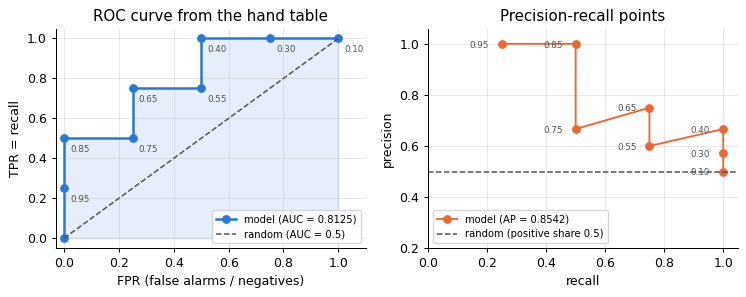

In [7]:
# Section 6 check: ROC points, AUC two ways, PR points and AP
fpr, tpr, thr = roc_curve(y8, p8, drop_intermediate=False)       # keep every threshold, like the hand table
hand_fpr = [0, 0, 0, 0.25, 0.25, 0.5, 0.5, 0.75, 1]
hand_tpr = [0, 0.25, 0.5, 0.5, 0.75, 0.75, 1, 1, 1]
print(pd.DataFrame({"threshold": thr, "FPR": fpr, "TPR": tpr}).T.round(2).to_string(header=False))
assert np.allclose(fpr, hand_fpr) and np.allclose(tpr, hand_tpr)
print("ROC points match the hand table: OK")

trapezoid = np.sum(np.diff(fpr) * (tpr[:-1] + tpr[1:]) / 2)        # sum of width x average height
check("AUC, trapezoid rule (numpy)", trapezoid, 0.8125)
check("AUC, trapezoid rule (scikit-learn auc)", auc(fpr, tpr), 0.8125)
check("AUC (scikit-learn roc_auc_score)", roc_auc_score(y8, p8), 0.8125)
pos, neg = p8[y8 == 1], p8[y8 == 0]
wins = (pos[:, None] > neg[None, :]).sum() + 0.5 * (pos[:, None] == neg[None, :]).sum()   # every pos-neg pair
check("pairs won (out of 16)", wins, 13, dp=0)
check("AUC = wins / 16", wins / (len(pos) * len(neg)), 0.8125)
check("average precision (scikit-learn)", average_precision_score(y8, p8), 0.8542)

order = np.argsort(p8)[::-1]                                      # hand PR points, threshold by threshold
TPc, FPc = np.cumsum(y8[order]), np.cumsum(1 - y8[order])
check("precision at t = 0.75", (TPc / (TPc + FPc))[2], 0.6667)
check("precision at t = 0.30", (TPc / (TPc + FPc))[6], 0.5714)
prec_sk, rec_sk, _ = precision_recall_curve(y8, p8, drop_intermediate=False)   # scikit-learn lists them in reverse
assert np.allclose(prec_sk[:-1][::-1], TPc / (TPc + FPc)) and np.allclose(rec_sk[:-1][::-1], TPc / 4)
print("all 8 precision-recall points match precision_recall_curve: OK")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.4, 3.4))
ax1.plot(fpr, tpr, "-o", color=BLUE, lw=2, ms=6, label="model (AUC = 0.8125)")
ax1.fill_between(fpr, tpr, step=None, color=BLUE, alpha=0.12)
ax1.plot([0, 1], [0, 1], "--", color=GRAY, lw=1.2, label="random (AUC = 0.5)")
for t, x, y in zip(thr[1:], fpr[1:], tpr[1:]):
    ax1.annotate(f"{t:.2f}", (x, y), textcoords="offset points", xytext=(5, -11), fontsize=7, color=GRAY)
ax1.set(xlabel="FPR (false alarms / negatives)", ylabel="TPR = recall", title="ROC curve from the hand table",
        xlim=(-0.03, 1.1))
ax1.legend(loc="lower right", fontsize=8)
rec_hand, prec_hand = TPc / 4, TPc / (TPc + FPc)                # the hand table, threshold by threshold
ax2.plot(rec_hand, prec_hand, "-o", color=ORANGE, lw=1.5, ms=6, label="model (AP = 0.8542)")
for t, x, y in zip(np.sort(p8)[::-1], rec_hand, prec_hand):
    ax2.annotate(f"{t:.2f}", (x, y), textcoords="offset points", xytext=(-26, -3), fontsize=7, color=GRAY)
ax2.axhline(0.5, ls="--", color=GRAY, lw=1.2, label="random (positive share 0.5)")
ax2.set(xlabel="recall", ylabel="precision", title="Precision-recall points", xlim=(0, 1.05), ylim=(0.2, 1.06))
ax2.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**Try it yourself.** Positives scored 0.9, 0.6, 0.35; negatives scored 0.7, 0.4, 0.2. Compute AUC by counting pairs and check it with the trapezoid rule.

<details><summary>Answer</summary>

Pairs: 0.9 beats 3 negatives, 0.6 beats 2 (0.4, 0.2), 0.35 beats 1 (0.2): $6/9 = 0.6667$. ROC points (sorted 0.9 P, 0.7 N, 0.6 P, 0.4 N, 0.35 P, 0.2 N): (0,0), (0,⅓), (⅓,⅓), (⅓,⅔), (⅔,⅔), (⅔,1), (1,1). Area $= \tfrac13 \cdot \tfrac13 + \tfrac13 \cdot \tfrac23 + \tfrac13 \cdot 1 = \tfrac{6}{9} = 0.6667$ ✓.
</details>

**Exam tip:** AUC depends only on the **order** of the scores, not their values: squaring every score, or dividing all by 2, leaves AUC unchanged. That is also why a model can have a great AUC and badly calibrated probabilities.

## 7. Multi-class confusion matrix: per-class metrics, macro, micro and weighted averages

**What it is:** with $K$ classes the confusion matrix is $K \times K$; we compute precision and recall for each class "one versus the rest", then average. **Analogy:** grading a school with three classrooms: *macro* averages the three classroom grades, *micro* pools every student together, *weighted* averages classrooms by their size.

### Problem

An animal-photo classifier was tested on 20 photos (rows = actual, columns = predicted):

| actual \ predicted | cat | dog | rabbit | row total (support) |
|---|---|---|---|---|
| **cat** | 8 | 1 | 1 | 10 |
| **dog** | 2 | 3 | 1 | 6 |
| **rabbit** | 0 | 1 | 3 | 4 |
| **column total** | 10 | 5 | 5 | 20 |

Compute accuracy, per-class precision, recall and F1, and the macro, micro and weighted averages.

### Solution by hand

1. For each class: TP = diagonal cell, FP = column total − TP (predicted as this class but wrong), FN = row total − TP (this class but predicted as another).

| class | TP | FP | FN | precision | recall | F1 $= \frac{2TP}{2TP+FP+FN}$ |
|---|---|---|---|---|---|---|
| cat | 8 | 10 − 8 = 2 | 10 − 8 = 2 | 8/10 = 0.8 | 8/10 = 0.8 | 16/20 = 0.8 |
| dog | 3 | 5 − 3 = 2 | 6 − 3 = 3 | 3/5 = 0.6 | 3/6 = 0.5 | 6/11 = 0.5455 |
| rabbit | 3 | 5 − 3 = 2 | 4 − 3 = 1 | 3/5 = 0.6 | 3/4 = 0.75 | 6/9 = 0.6667 |

2. Accuracy = diagonal / total $= (8 + 3 + 3)/20 = 14/20 = 0.7$.
3. **Macro** average (every class counts the same):
   - precision $= (0.8 + 0.6 + 0.6)/3 = 0.6667$
   - recall $= (0.8 + 0.5 + 0.75)/3 = 2.05/3 = 0.6833$
   - F1 $= (0.8 + 0.545455 + 0.666667)/3 = 2.012121/3 = 0.6707$
4. **Weighted** average (weights = support 10, 6, 4):
   - precision $= (10 \times 0.8 + 6 \times 0.6 + 4 \times 0.6)/20 = (8 + 3.6 + 2.4)/20 = 0.7$
   - recall $= (10 \times 0.8 + 6 \times 0.5 + 4 \times 0.75)/20 = (8 + 3 + 3)/20 = 0.7$
   - F1 $= (10 \times 0.8 + 6 \times 0.545455 + 4 \times 0.666667)/20 = (8 + 3.272727 + 2.666667)/20 = 13.939394/20 = 0.6970$
5. **Micro** average (pool the counts of all classes first): TP $= 8+3+3 = 14$, FP $= 2+2+2 = 6$, FN $= 2+3+1 = 6$. Precision $= 14/20 = 0.7$, recall $= 14/20 = 0.7$, F1 $= 0.7$.
6. Notice: with one label per sample, micro precision = micro recall = micro F1 = accuracy, and weighted recall = accuracy too. Macro F1 (0.6707) is the lowest because it gives the weak small class (dog) a full third of the vote.

In [8]:
# Section 7 check: rebuild the 20 labels from the matrix, then let scikit-learn compute everything
classes = ["cat", "dog", "rabbit"]
M = np.array([[8, 1, 1],
              [2, 3, 1],
              [0, 1, 3]])
yt = np.repeat(np.repeat(np.arange(3), 3), M.ravel())     # actual label of every photo
yp = np.repeat(np.tile(np.arange(3), 3), M.ravel())       # predicted label of every photo
assert (confusion_matrix(yt, yp) == M).all()

prec_c, rec_c, f1_c, support = precision_recall_fscore_support(yt, yp)
print(pd.DataFrame({"precision": prec_c, "recall": rec_c, "F1": f1_c, "support": support}, index=classes).round(4))
for c, (hp, hr, hf) in enumerate([(0.8, 0.8, 0.8), (0.6, 0.5, 0.5455), (0.6, 0.75, 0.6667)]):
    check(f"{classes[c]} precision", prec_c[c], hp)
    check(f"{classes[c]} recall", rec_c[c], hr)
    check(f"{classes[c]} F1", f1_c[c], hf)
check("accuracy", accuracy_score(yt, yp), 0.7)
check("macro precision", precision_score(yt, yp, average="macro"), 0.6667)
check("macro recall", recall_score(yt, yp, average="macro"), 0.6833)
check("macro F1", f1_score(yt, yp, average="macro"), 0.6707)
check("weighted precision", precision_score(yt, yp, average="weighted"), 0.7)
check("weighted F1", f1_score(yt, yp, average="weighted"), 0.6970)
check("micro F1 (= accuracy)", f1_score(yt, yp, average="micro"), 0.7)

        precision  recall      F1  support
cat           0.8    0.80  0.8000       10
dog           0.6    0.50  0.5455        6
rabbit        0.6    0.75  0.6667        4
cat precision                            code =      0.8000   by hand =      0.8000   OK
cat recall                               code =      0.8000   by hand =      0.8000   OK
cat F1                                   code =      0.8000   by hand =      0.8000   OK
dog precision                            code =      0.6000   by hand =      0.6000   OK
dog recall                               code =      0.5000   by hand =      0.5000   OK
dog F1                                   code =      0.5455   by hand =      0.5455   OK
rabbit precision                         code =      0.6000   by hand =      0.6000   OK
rabbit recall                            code =      0.7500   by hand =      0.7500   OK
rabbit F1                                code =      0.6667   by hand =      0.6667   OK
accuracy                   

**Try it yourself.** Rows = actual A, B, C; columns = predicted A, B, C: `[[4, 1, 0], [1, 3, 1], [0, 2, 8]]`. Compute accuracy, the F1 of each class, and macro, weighted and micro F1.

<details><summary>Answer</summary>

Column totals 5, 6, 9; row totals 5, 5, 10. Accuracy $= 15/20 = 0.75$.
A: P $= 4/5$, R $= 4/5$, F1 $= 0.8$. B: P $= 3/6 = 0.5$, R $= 3/5 = 0.6$, F1 $= 6/11 = 0.5455$. C: P $= 8/9 = 0.8889$, R $= 8/10 = 0.8$, F1 $= 16/19 = 0.8421$.
Macro F1 $= (0.8 + 0.545455 + 0.842105)/3 = 0.7292$; weighted F1 $= (5 \times 0.8 + 5 \times 0.545455 + 10 \times 0.842105)/20 = 0.7574$; micro F1 = accuracy $= 0.75$.
</details>

**Exam tip:** use **macro** when every class matters equally (rare diseases), **weighted** when you want the average over samples but still per-class detail, and remember **micro = accuracy** for ordinary multi-class problems.

## 8. Log loss (binary cross-entropy)

**What it is:** a score for **probabilities**, not just labels: it is small when the model gives a high probability to what really happened, and huge when it was confidently wrong. **Analogy:** a weather app that said "99% sunny" on a day of heavy rain should lose far more trust than one that said "60% sunny".

### Problem

| sample | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| actual $y$ | 1 | 0 | 1 | 0 |
| predicted $p = P(y = 1)$ | 0.9 | 0.2 | 0.5 | 0.7 |

Compute each sample's loss and the mean log loss. Then: what does one confident mistake ($y = 1$, $p = 0.01$) cost? What is the loss for a 3-class prediction $(0.7, 0.2, 0.1)$ when the true class is the first?

### Solution by hand

1. Formula (natural log): $\ell = -\left[y \ln p + (1-y)\ln(1-p)\right]$, so $\ell = -\ln p$ when $y = 1$ and $\ell = -\ln(1-p)$ when $y = 0$. In words: minus the log of the probability given to the **true** class.
2. Per sample:

| sample | $y$ | $p$ | probability of the true class | $\ell = -\ln(\cdot)$ |
|---|---|---|---|---|
| 1 | 1 | 0.9 | 0.9 | 0.1054 |
| 2 | 0 | 0.2 | 1 − 0.2 = 0.8 | 0.2231 |
| 3 | 1 | 0.5 | 0.5 | 0.6931 |
| 4 | 0 | 0.7 | 1 − 0.7 = 0.3 | 1.2040 |

3. Mean: $(0.1054 + 0.2231 + 0.6931 + 1.2040)/4 = 2.2256/4 = 0.5564$.
4. A confident mistake: $-\ln 0.01 = 4.6052$, as much as about 44 confident correct answers at $p = 0.9$ ($4.6052 / 0.1054 \approx 43.7$). Always answering $p = 0.5$ gives $\ln 2 = 0.6931$, the "know-nothing" baseline.
5. Multi-class cross-entropy uses the same rule, minus the log of the true class's probability: $-\ln 0.7 = 0.3567$.

In [9]:
# Section 8 check
y4 = np.array([1, 0, 1, 0])
p4 = np.array([0.9, 0.2, 0.5, 0.7])
per_sample = -(y4 * np.log(p4) + (1 - y4) * np.log(1 - p4))
for i, (v, h) in enumerate(zip(per_sample, [0.1054, 0.2231, 0.6931, 1.2040]), 1):
    check(f"loss of sample {i}", v, h)
check("mean log loss (numpy)", per_sample.mean(), 0.5564)
check("mean log loss (scikit-learn)", log_loss(y4, p4), 0.5564)
check("confident mistake -ln(0.01)", -np.log(0.01), 4.6052)
check("always 0.5: ln 2", log_loss(y4, np.full(4, 0.5)), 0.6931)
check("3-class: -ln(0.7)", log_loss([0], [[0.7, 0.2, 0.1]], labels=[0, 1, 2]), 0.3567)

loss of sample 1                         code =      0.1054   by hand =      0.1054   OK
loss of sample 2                         code =      0.2231   by hand =      0.2231   OK
loss of sample 3                         code =      0.6931   by hand =      0.6931   OK
loss of sample 4                         code =      1.2040   by hand =      1.2040   OK
mean log loss (numpy)                    code =      0.5564   by hand =      0.5564   OK
mean log loss (scikit-learn)             code =      0.5564   by hand =      0.5564   OK
confident mistake -ln(0.01)              code =      4.6052   by hand =      4.6052   OK
always 0.5: ln 2                         code =      0.6931   by hand =      0.6931   OK
3-class: -ln(0.7)                        code =      0.3567   by hand =      0.3567   OK


**Try it yourself.** $y = (1, 0, 1)$ and $p = (0.8, 0.3, 0.4)$. Compute the mean log loss.

<details><summary>Answer</summary>

Losses: $-\ln 0.8 = 0.2231$, $-\ln 0.7 = 0.3567$, $-\ln 0.4 = 0.9163$. Mean $= 1.4961/3 = 0.4987$.
</details>

**Common mistake:** using $\log_{10}$ or $\log_2$. scikit-learn and almost every ML library use the natural log $\ln$; the answers differ by a constant factor.

---
## Part B. Regression: metrics, linear regression and gradient descent

## 9. Regression metrics: MAE, MSE, RMSE, R² and MAPE

**What they are:** ways to summarize how far numeric predictions are from the truth. **Analogy:** darts. MAE is the average distance from the bullseye; MSE/RMSE punish the wild throws much more; R² compares you with a player who always aims at the middle of the board (the mean).

### Problem

| point | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| actual $y$ | 3 | 5 | 2 | 7 | 8 |
| predicted $\hat y$ | 2.5 | 5 | 3 | 8 | 6.5 |

Compute MAE, MSE, RMSE, R² and MAPE.

### Solution by hand

1. Error table, with $e = y - \hat y$:

| point | $e$ | $\lvert e\rvert$ | $e^2$ | $\lvert e\rvert / y$ |
|---|---|---|---|---|
| 1 | 0.5 | 0.5 | 0.25 | 0.5/3 = 0.166667 |
| 2 | 0 | 0 | 0 | 0 |
| 3 | −1 | 1 | 1 | 1/2 = 0.5 |
| 4 | −1 | 1 | 1 | 1/7 = 0.142857 |
| 5 | 1.5 | 1.5 | 2.25 | 1.5/8 = 0.1875 |
| **sum** | | **4** | **4.5** | **0.997024** |

2. $\text{MAE} = \frac{1}{n}\sum \lvert e \rvert = 4/5 = 0.8$
3. $\text{MSE} = \frac{1}{n}\sum e^2 = 4.5/5 = 0.9$, and $\text{RMSE} = \sqrt{0.9} = 0.9487$ (back in the units of $y$)
4. $R^2 = 1 - \dfrac{SS_{res}}{SS_{tot}}$ with $\bar y = 25/5 = 5$:
   - $SS_{tot} = \sum (y - \bar y)^2 = (-2)^2 + 0^2 + (-3)^2 + 2^2 + 3^2 = 4 + 0 + 9 + 4 + 9 = 26$
   - $SS_{res} = \sum e^2 = 4.5$
   - $R^2 = 1 - 4.5/26 = 1 - 0.1731 = 0.8269$: the model removes about 83% of the squared error of "always predict the mean".
5. $\text{MAPE} = \frac{1}{n}\sum \frac{\lvert e \rvert}{\lvert y \rvert} = 0.997024/5 = 0.1994$, about 19.94%.

In [10]:
# Section 9 check
y_r = np.array([3, 5, 2, 7, 8.0])
yhat_r = np.array([2.5, 5, 3, 8, 6.5])
check("MAE", mean_absolute_error(y_r, yhat_r), 0.8)
check("MSE", mean_squared_error(y_r, yhat_r), 0.9)
check("RMSE", root_mean_squared_error(y_r, yhat_r), 0.9487)
check("SS_tot", ((y_r - y_r.mean()) ** 2).sum(), 26, dp=0)
check("R^2", r2_score(y_r, yhat_r), 0.8269)
check("MAPE (as a fraction)", mean_absolute_percentage_error(y_r, yhat_r), 0.1994)

MAE                                      code =      0.8000   by hand =      0.8000   OK
MSE                                      code =      0.9000   by hand =      0.9000   OK
RMSE                                     code =      0.9487   by hand =      0.9487   OK
SS_tot                                   code =          26   by hand =          26   OK
R^2                                      code =      0.8269   by hand =      0.8269   OK
MAPE (as a fraction)                     code =      0.1994   by hand =      0.1994   OK


**Try it yourself.** $y = (10, 20, 30, 40)$, $\hat y = (12, 18, 33, 37)$. Compute MAE, MSE, RMSE, R² and MAPE.

<details><summary>Answer</summary>

Errors $(-2, 2, -3, 3)$. MAE $= 10/4 = 2.5$; MSE $= (4 + 4 + 9 + 9)/4 = 6.5$; RMSE $= \sqrt{6.5} = 2.5495$; $\bar y = 25$, $SS_{tot} = 225 + 25 + 25 + 225 = 500$, $R^2 = 1 - 26/500 = 0.948$; MAPE $= (0.2 + 0.1 + 0.1 + 0.075)/4 = 0.11875$ (11.875%).
</details>

**Exam tip:** RMSE ≥ MAE always; a big gap between them means a few large errors. MAPE breaks when some $y = 0$ (division by zero), and $R^2$ can be negative on test data when the model is worse than predicting the mean.

## 10. Simple linear regression by hand (least squares)

**What it is:** the straight line $\hat y = wx + b$ that makes the sum of squared vertical errors as small as possible. **Analogy:** a stiff ruler laid through a cloud of points, held by springs to every point; it settles where the total spring stretch (squared) is smallest.

### Problem

Hours studied $x$ and quiz score $y$ (out of 10) for 5 students:

| $x$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $y$ | 2 | 4 | 5 | 4 | 5 |

Find the least-squares slope and intercept, predict the score for 6 hours, and compute $R^2$.

### Solution by hand

1. Sums table ($n = 5$):

| $x$ | $y$ | $xy$ | $x^2$ |
|---|---|---|---|
| 1 | 2 | 2 | 1 |
| 2 | 4 | 8 | 4 |
| 3 | 5 | 15 | 9 |
| 4 | 4 | 16 | 16 |
| 5 | 5 | 25 | 25 |
| $\Sigma x = 15$ | $\Sigma y = 20$ | $\Sigma xy = 66$ | $\Sigma x^2 = 55$ |

2. Slope: $w = \dfrac{n\Sigma xy - \Sigma x \Sigma y}{n \Sigma x^2 - (\Sigma x)^2} = \dfrac{5 \times 66 - 15 \times 20}{5 \times 55 - 15^2} = \dfrac{330 - 300}{275 - 225} = \dfrac{30}{50} = 0.6$
   Same with deviations: $x - \bar x = (-2, -1, 0, 1, 2)$, $y - \bar y = (-2, 0, 1, 0, 1)$, so $w = \dfrac{\Sigma (x-\bar x)(y - \bar y)}{\Sigma (x - \bar x)^2} = \dfrac{4 + 0 + 0 + 0 + 2}{4 + 1 + 0 + 1 + 4} = \dfrac{6}{10} = 0.6$ ✓
3. Intercept: $b = \bar y - w \bar x = 4 - 0.6 \times 3 = 2.2$. Line: $\hat y = 0.6x + 2.2$.
4. Prediction for $x = 6$: $0.6 \times 6 + 2.2 = 5.8$.
5. $R^2$: predictions $(2.8, 3.4, 4.0, 4.6, 5.2)$, residuals $y - \hat y = (-0.8, 0.6, 1.0, -0.6, -0.2)$, $SS_{res} = 0.64 + 0.36 + 1 + 0.36 + 0.04 = 2.4$; $SS_{tot} = 4 + 0 + 1 + 0 + 1 = 6$; $R^2 = 1 - 2.4/6 = 0.6$.

In [11]:
# Section 10 check
x10 = np.array([1, 2, 3, 4, 5.0])
y10 = np.array([2, 4, 5, 4, 5.0])
n = len(x10)
w_hand = (n * (x10 * y10).sum() - x10.sum() * y10.sum()) / (n * (x10 ** 2).sum() - x10.sum() ** 2)
lin = LinearRegression().fit(x10.reshape(-1, 1), y10)
check("slope (sums formula)", w_hand, 0.6)
check("slope (scikit-learn)", lin.coef_[0], 0.6)
check("intercept (scikit-learn)", lin.intercept_, 2.2)
check("prediction at x = 6", lin.predict([[6.0]])[0], 5.8)
check("R^2", r2_score(y10, lin.predict(x10.reshape(-1, 1))), 0.6)

slope (sums formula)                     code =      0.6000   by hand =      0.6000   OK
slope (scikit-learn)                     code =      0.6000   by hand =      0.6000   OK
intercept (scikit-learn)                 code =      2.2000   by hand =      2.2000   OK
prediction at x = 6                      code =      5.8000   by hand =      5.8000   OK
R^2                                      code =      0.6000   by hand =      0.6000   OK


**Try it yourself.** $x = (1, 2, 3, 4)$, $y = (3, 5, 7, 10)$. Find the slope, intercept and the prediction at $x = 5$.

<details><summary>Answer</summary>

$\Sigma x = 10$, $\Sigma y = 25$, $\Sigma xy = 74$, $\Sigma x^2 = 30$, $n = 4$. $w = (4 \times 74 - 10 \times 25)/(4 \times 30 - 100) = 46/20 = 2.3$; $b = 6.25 - 2.3 \times 2.5 = 0.5$; $\hat y(5) = 0.5 + 11.5 = 12.0$.
</details>

**Exam tip:** the least-squares line always passes through $(\bar x, \bar y)$; plug it in as a 5-second check of your answer.

## 11. The cost function $J(w,b)$ and gradient descent, step by step

**What it is:** the **cost function** $J(w, b) = \frac{1}{2m}\sum_{i=1}^{m} \big(f(x_i) - y_i\big)^2$ measures how badly the line $f(x) = wx + b$ fits ($m$ = number of examples). **Gradient descent** lowers it step by step: $w := w - \alpha \frac{\partial J}{\partial w}$, $b := b - \alpha \frac{\partial J}{\partial b}$, where $\alpha$ is the **learning rate**. **Analogy:** walking down a foggy hill: you can't see the valley, but you can feel the slope under your feet and step downhill; $\alpha$ is your stride length.

Derivatives (the $\frac12$ cancels the 2 from the square):
$$\frac{\partial J}{\partial w} = \frac{1}{m}\sum_i \big(f(x_i) - y_i\big)\,x_i, \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_i \big(f(x_i) - y_i\big)$$

### Problem

Taxi rides: distance $x$ (km) and fare $y$ (dollars). The true rule is "1 dollar plus 2 dollars per km", but the model has to discover it.

| ride | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| $x$ (km) | 1 | 2 | 3 | 4 |
| $y$ (dollars) | 3 | 5 | 7 | 9 |

(a) Compute $J(0, 0)$, $J(2, 0)$ and $J(2, 1)$. (b) Run 3 iterations of batch gradient descent from $w = b = 0$ with $\alpha = 0.1$.

### Solution by hand

1. $m = 4$, so $\frac{1}{2m} = \frac18$.
   - $J(0,0)$: errors $f - y = (-3, -5, -7, -9)$, squares $9 + 25 + 49 + 81 = 164$, $J = 164/8 = 20.5$
   - $J(2,0)$: $f = (2, 4, 6, 8)$, errors $(-1, -1, -1, -1)$, $J = 4/8 = 0.5$
   - $J(2,1)$: $f = (3, 5, 7, 9) = y$, $J = 0$, the perfect fit that gradient descent should move towards.
2. **Iteration 1** from $(w, b) = (0, 0)$: errors $e = f - y = (-3, -5, -7, -9)$.
   $\sum e\,x = (-3)(1) + (-5)(2) + (-7)(3) + (-9)(4) = -3 - 10 - 21 - 36 = -70$, so $\frac{\partial J}{\partial w} = -70/4 = -17.5$
   $\sum e = -24$, so $\frac{\partial J}{\partial b} = -24/4 = -6$
   Update: $w = 0 - 0.1 \times (-17.5) = 1.75$, $b = 0 - 0.1 \times (-6) = 0.6$
3. **Iteration 2** from $(1.75, 0.6)$: $f = 1.75x + 0.6 = (2.35, 4.1, 5.85, 7.6)$, errors $(-0.65, -0.9, -1.15, -1.4)$.
   $\sum e\,x = -0.65 - 1.8 - 3.45 - 5.6 = -11.5$, $\frac{\partial J}{\partial w} = -2.875$; $\sum e = -4.1$, $\frac{\partial J}{\partial b} = -1.025$
   Update: $w = 1.75 + 0.2875 = 2.0375$, $b = 0.6 + 0.1025 = 0.7025$
4. **Iteration 3** from $(2.0375, 0.7025)$: $f = (2.74, 4.7775, 6.815, 8.8525)$, errors $(-0.26, -0.2225, -0.185, -0.1475)$.
   $\sum e\,x = -0.26 - 0.445 - 0.555 - 0.59 = -1.85$, $\frac{\partial J}{\partial w} = -0.4625$; $\sum e = -0.815$, $\frac{\partial J}{\partial b} = -0.20375$
   Update: $w = 2.0375 + 0.04625 = 2.08375$, $b = 0.7025 + 0.020375 = 0.722875$
5. Cost after each iteration ($w$, $b$ and the errors are exact decimals; $J$ is rounded to 6 decimals):

| after iteration | $w$ | $b$ | errors $f - y$ | $\sum e^2$ | $J = \sum e^2 / 8$ |
|---|---|---|---|---|---|
| 0 (start) | 0 | 0 | −3, −5, −7, −9 | 164 | 20.5 |
| 1 | 1.75 | 0.6 | −0.65, −0.9, −1.15, −1.4 | 4.515 | 0.564375 |
| 2 | 2.0375 | 0.7025 | −0.26, −0.2225, −0.185, −0.1475 | 0.1730875 | 0.021636 |
| 3 | 2.08375 | 0.722875 | −0.193375, −0.109625, −0.025875, 0.057875 | 0.0534306 | 0.006679 |

6. $J$ falls fast: 20.5 → 0.564375 → 0.021636 → 0.006679. $w$ overshoots 2 a little while $b$ is still climbing towards 1; with more iterations they settle at $(2, 1)$.

In [12]:
# Section 11 check: batch gradient descent, exactly as on paper
x_taxi = np.array([1, 2, 3, 4.0])
y_taxi = np.array([3, 5, 7, 9.0])

def cost(w, b, x=x_taxi, y=y_taxi):
    return ((w * x + b - y) ** 2).sum() / (2 * len(x))        # J(w,b) = 1/(2m) * sum of squared errors

check("J(0,0)", cost(0, 0), 20.5)
check("J(2,0)", cost(2, 0), 0.5)
check("J(2,1)", cost(2, 1), 0.0)

w, b, alpha = 0.0, 0.0, 0.1
hand = [(1.75, 0.6, 0.564375), (2.0375, 0.7025, 0.021636), (2.08375, 0.722875, 0.006679)]
for it, (hw, hb, hJ) in enumerate(hand, 1):
    e = w * x_taxi + b - y_taxi                 # errors with the OLD w, b
    dw, db = (e * x_taxi).mean(), e.mean()      # both gradients first ...
    w, b = w - alpha * dw, b - alpha * db       # ... then update both at once
    print(f"iteration {it}: dJ/dw = {dw:.5f}, dJ/db = {db:.5f}")
    check("   w", w, hw, dp=6); check("   b", b, hb, dp=6); check("   J", cost(w, b), hJ, dp=6)

for _ in range(5000):                          # keep going: it converges to the least-squares line
    e = w * x_taxi + b - y_taxi
    w, b = w - alpha * (e * x_taxi).mean(), b - alpha * e.mean()
lr_taxi = LinearRegression().fit(x_taxi.reshape(-1, 1), y_taxi)
print(f"after 5003 iterations: w = {w:.6f}, b = {b:.6f};  LinearRegression: w = {lr_taxi.coef_[0]:.6f}, b = {lr_taxi.intercept_:.6f}")
assert np.isclose(w, 2) and np.isclose(b, 1)

J(0,0)                                   code =     20.5000   by hand =     20.5000   OK
J(2,0)                                   code =      0.5000   by hand =      0.5000   OK
J(2,1)                                   code =      0.0000   by hand =      0.0000   OK
iteration 1: dJ/dw = -17.50000, dJ/db = -6.00000
   w                                     code =    1.750000   by hand =    1.750000   OK
   b                                     code =    0.600000   by hand =    0.600000   OK
   J                                     code =    0.564375   by hand =    0.564375   OK
iteration 2: dJ/dw = -2.87500, dJ/db = -1.02500
   w                                     code =    2.037500   by hand =    2.037500   OK
   b                                     code =    0.702500   by hand =    0.702500   OK
   J                                     code =    0.021636   by hand =    0.021636   OK
iteration 3: dJ/dw = -0.46250, dJ/db = -0.20375
   w                                     code =    2.0

**Try it yourself.** Data $x = (1, 2)$, $y = (2, 4)$, start $w = b = 0$, $\alpha = 0.1$. Compute $J(0,0)$, one gradient descent step, and $J$ after the step.

<details><summary>Answer</summary>

$J(0,0) = (4 + 16)/4 = 5$. Errors $(-2, -4)$: $\frac{\partial J}{\partial w} = (-2 - 8)/2 = -5$, $\frac{\partial J}{\partial b} = -6/2 = -3$. New $w = 0.5$, $b = 0.3$. Now $f = (0.8, 1.3)$, errors $(-1.2, -2.7)$, $J = (1.44 + 7.29)/4 = 2.1825$.
</details>

**Common mistake:** updating $w$ first and then using the *new* $w$ to compute the gradient for $b$. Compute both gradients from the old $(w, b)$, then update both ("simultaneous update"). Also, the $\frac12$ in $J$ only tidies the derivative; some books use plain MSE $\frac{1}{m}\sum e^2$, whose gradient is twice as big.

## 12. The learning rate: too small, good, too large

**What it is:** $\alpha$ sets the step size of gradient descent. Too small: progress is slow. Too large: each step jumps over the valley and lands higher up, so $J$ grows (divergence). **Analogy:** parking a car: creeping forward a centimetre at a time takes forever; flooring the accelerator puts you through the wall.

### Problem

Same taxi data and start $(w, b) = (0, 0)$. Do **one** gradient descent step with $\alpha = 0.01$, $0.1$ and $0.3$ and compare $J$ after the step with $J(0,0) = 20.5$. Then (code) watch 10 iterations.

### Solution by hand

1. The gradient at $(0,0)$ does not depend on $\alpha$: $\left(\frac{\partial J}{\partial w}, \frac{\partial J}{\partial b}\right) = (-17.5, -6)$ (from Section 11).
2. New parameters $w = 0 + 17.5\alpha$, $b = 0 + 6\alpha$, and the cost after the step:

| $\alpha$ | new $w$ | new $b$ | errors $f - y$ | $\sum e^2$ | $J$ after | verdict |
|---|---|---|---|---|---|---|
| 0.01 | 0.175 | 0.06 | −2.765, −4.59, −6.415, −8.24 | 137.76315 | 17.2204 | down a little: too small, slow |
| 0.1 | 1.75 | 0.6 | −0.65, −0.9, −1.15, −1.4 | 4.515 | 0.5644 | down a lot: good |
| 0.3 | 5.25 | 1.8 | 4.05, 7.3, 10.55, 13.8 | 371.435 | 46.4294 | **up** from 20.5: too large |

   Example for $\alpha = 0.3$: $f(1) = 5.25 + 1.8 = 7.05$, error $7.05 - 3 = 4.05$; the other errors follow the same way, and $J = 371.435/8 = 46.4294$.
3. With $\alpha = 0.3$ the line went from far too flat ($w = 0$) to far too steep ($w = 5.25$): it overshot. The next step overshoots even more, so $J$ keeps growing (20.5 → 46.43 → 105.17 → ...).
4. Practical recipe: try $\alpha$ = 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1 and keep the largest one for which $J$ goes down at **every** iteration.

J after 1 step, alpha = 0.01             code =     17.2204   by hand =     17.2204   OK
J after 1 step, alpha = 0.1              code =      0.5644   by hand =      0.5644   OK
J after 1 step, alpha = 0.3              code =     46.4294   by hand =     46.4294   OK

J for iterations 0..4:
   alpha=0.01  alpha=0.1  alpha=0.3
0     20.5000    20.5000    20.5000
1     17.2204     0.5644    46.4294
2     14.4656     0.0216   105.1680
3     12.1517     0.0067   238.2294
4     10.2081     0.0061   539.6541


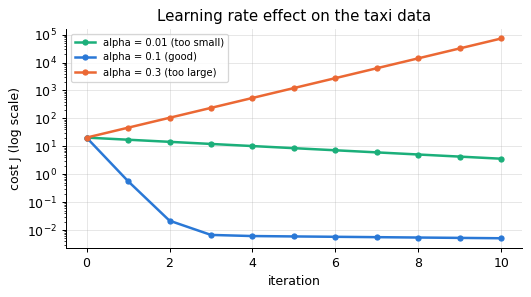

In [13]:
# Section 12 check: one step for each alpha, then 10 iterations and a plot of J
def run_gd(alpha, iters, x=x_taxi, y=y_taxi):
    w = b = 0.0
    history = [cost(w, b, x, y)]
    for _ in range(iters):
        e = w * x + b - y
        w, b = w - alpha * (e * x).mean(), b - alpha * e.mean()
        history.append(cost(w, b, x, y))
    return np.array(history)

for alpha, hJ in [(0.01, 17.2204), (0.1, 0.5644), (0.3, 46.4294)]:
    check(f"J after 1 step, alpha = {alpha}", run_gd(alpha, 1)[1], hJ)

curves = {a: run_gd(a, 10) for a in [0.01, 0.1, 0.3]}
print("\nJ for iterations 0..4:")
print(pd.DataFrame({f"alpha={a}": c[:5] for a, c in curves.items()}).round(4).to_string())
assert np.all(np.diff(curves[0.01]) < 0) and np.all(np.diff(curves[0.1]) < 0)   # always down
assert np.all(np.diff(curves[0.3]) > 0)                                          # always up: diverging

fig, ax = plt.subplots(figsize=(6, 3.4))
for (a, c), col, lab in zip(curves.items(), [AQUA, BLUE, ORANGE], ["too small", "good", "too large"]):
    ax.plot(range(len(c)), c, "-o", ms=4, lw=2, color=col, label=f"alpha = {a} ({lab})")
ax.set_yscale("log")
ax.set(xlabel="iteration", ylabel="cost J (log scale)", title="Learning rate effect on the taxi data")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Try it yourself.** With the data $x = (1, 2)$, $y = (2, 4)$ from Section 11's exercise, do one step from $(0,0)$ with $\alpha = 1$. Is $\alpha = 1$ too large?

<details><summary>Answer</summary>

The gradient is $(-5, -3)$, so $w = 5$, $b = 3$. Then $f = (8, 13)$, errors $(6, 9)$, $J = (36 + 81)/4 = 29.25 > J(0,0) = 5$. Yes, $\alpha = 1$ is too large: $J$ went up.
</details>

**Exam tip:** if $J$ increases, first suspect a learning rate that is too large, then a sign bug ($w + \alpha \cdot$ gradient instead of minus). If $J$ decreases but painfully slowly, increase $\alpha$ (or scale the features, Section 14).

## 13. Batch vs stochastic vs mini-batch gradient descent

**What it is:** the three differ only in **how many examples** are averaged for each update. *Batch* GD uses all $m$ examples (1 update per pass), *stochastic* GD (SGD) uses 1 example ($m$ updates per pass), *mini-batch* uses a small group. **Analogy:** asking for directions: ask the whole village and then take one careful step (batch), or ask one passer-by after every step (SGD): faster but zig-zaggy.

An **epoch** is one pass over all training examples. For one example the gradients are just $(f - y)\,x$ and $(f - y)$.

### Problem

Taxi data, $\alpha = 0.1$, start $(w, b) = (0, 0)$. Do **one epoch** of (a) batch GD, (b) SGD with the rides in order 1, 2, 3, 4, (c) mini-batch GD with batch size 2: rides {1, 2} then {3, 4}. Compare $J$ after the epoch.

### Solution by hand

1. **Batch GD:** one update, already done in Section 11: $(w, b) = (1.75, 0.6)$, $J = 0.564375$.
2. **SGD:** four updates, each from a single ride:

| step | ride $(x, y)$ | $f = wx + b$ | $e = f - y$ | $w := w - 0.1\,e\,x$ | $b := b - 0.1\,e$ |
|---|---|---|---|---|---|
| 1 | (1, 3) | 0 | −3 | 0 + 0.3 = 0.3 | 0 + 0.3 = 0.3 |
| 2 | (2, 5) | 0.3 × 2 + 0.3 = 0.9 | −4.1 | 0.3 + 0.82 = 1.12 | 0.3 + 0.41 = 0.71 |
| 3 | (3, 7) | 1.12 × 3 + 0.71 = 4.07 | −2.93 | 1.12 + 0.879 = 1.999 | 0.71 + 0.293 = 1.003 |
| 4 | (4, 9) | 1.999 × 4 + 1.003 = 8.999 | −0.001 | 1.999 + 0.0004 = 1.9994 | 1.003 + 0.0001 = 1.0031 |

   After the epoch: $f = (3.0025, 5.0019, 7.0013, 9.0007)$, $\sum e^2 = 0.00001204$, $J = 0.0000015$, almost perfect.
3. **Mini-batch (size 2):** two updates, each the average over 2 rides:

| update | rides | $f$ | $e = f - y$ | $\frac{\partial J}{\partial w}$ = mean of $e\,x$ | $\frac{\partial J}{\partial b}$ = mean of $e$ | new $w$ | new $b$ |
|---|---|---|---|---|---|---|---|
| 1 | 1, 2 | 0, 0 | −3, −5 | (−3 − 10)/2 = −6.5 | (−3 − 5)/2 = −4 | 0.65 | 0.4 |
| 2 | 3, 4 | 2.35, 3.0 | −4.65, −6 | (−13.95 − 24)/2 = −18.975 | (−4.65 − 6)/2 = −5.325 | 0.65 + 1.8975 = 2.5475 | 0.4 + 0.5325 = 0.9325 |

   After the epoch: errors $(0.48, 1.0275, 1.575, 2.1225)$, $\sum e^2 = 8.2717875$, $J = 1.033973$.
4. Comparison after one epoch:

| method | updates per epoch | $(w, b)$ after 1 epoch | $J$ |
|---|---|---|---|
| batch GD | 1 | (1.75, 0.6) | 0.564375 |
| mini-batch, size 2 | 2 | (2.5475, 0.9325) | 1.033973 |
| SGD, size 1 | 4 | (1.9994, 1.0031) | 0.0000015 |

5. More updates per epoch usually means more progress per pass over the data, but each update is based on less information, so the path is **noisy**: the mini-batch run overshot $w$, and SGD's near-perfect result is partly luck of the order. The code below runs SGD in the order 4, 3, 2, 1 and ends somewhere else. In practice mini-batches of 32 to 512 examples are the usual compromise: fast vectorized maths and many updates per epoch.

In [14]:
# Section 13 check: one epoch of each method
alpha = 0.1

def gd_epoch(batches, x=x_taxi, y=y_taxi):
    """One epoch: one update per batch of indices; gradient = average over the batch."""
    w = b = 0.0
    for idx in batches:
        e = w * x[idx] + b - y[idx]
        w, b = w - alpha * (e * x[idx]).mean(), b - alpha * e.mean()
    return w, b

results = {"batch GD": gd_epoch([[0, 1, 2, 3]]),
           "mini-batch (2)": gd_epoch([[0, 1], [2, 3]]),
           "SGD order 1,2,3,4": gd_epoch([[0], [1], [2], [3]]),
           "SGD order 4,3,2,1": gd_epoch([[3], [2], [1], [0]])}
hand = {"batch GD": (1.75, 0.6, 0.564375, 6), "mini-batch (2)": (2.5475, 0.9325, 1.033973, 6),
        "SGD order 1,2,3,4": (1.9994, 1.0031, 0.0000015, 7)}       # (w, b, J, decimals of J)
for name, (w, b) in results.items():
    print(f"{name:18}: w = {w:.6f}, b = {b:.6f}, J = {cost(w, b):.7f}")
    if name in hand:
        hw, hb, hJ, dpJ = hand[name]
        check("   w", w, hw, dp=6); check("   b", b, hb, dp=6); check("   J", cost(w, b), hJ, dp=dpJ)

batch GD          : w = 1.750000, b = 0.600000, J = 0.5643750
   w                                     code =    1.750000   by hand =    1.750000   OK
   b                                     code =    0.600000   by hand =    0.600000   OK
   J                                     code =    0.564375   by hand =    0.564375   OK
mini-batch (2)    : w = 2.547500, b = 0.932500, J = 1.0339734
   w                                     code =    2.547500   by hand =    2.547500   OK
   b                                     code =    0.932500   by hand =    0.932500   OK
   J                                     code =    1.033973   by hand =    1.033973   OK
SGD order 1,2,3,4 : w = 1.999400, b = 1.003100, J = 0.0000015
   w                                     code =    1.999400   by hand =    1.999400   OK
   b                                     code =    1.003100   by hand =    1.003100   OK
   J                                     code =   0.0000015   by hand =   0.0000015   OK
SGD order 4,3

**Try it yourself.** Data $x = (1, 2)$, $y = (2, 4)$, $\alpha = 0.1$, start $(0, 0)$. Do one epoch of SGD in the order 1, 2.

<details><summary>Answer</summary>

Step 1: $f = 0$, $e = -2$: $w = 0.2$, $b = 0.2$. Step 2: $f = 0.2 \times 2 + 0.2 = 0.6$, $e = -3.4$: $w = 0.2 + 0.1 \times 3.4 \times 2 = 0.88$, $b = 0.2 + 0.34 = 0.54$.
</details>

**Exam tip:** "epoch" = one pass through all the training data; "iteration" = one parameter update. Batch GD does 1 iteration per epoch, SGD does $m$, mini-batch does $m / \text{batch size}$ (rounded up).

## 14. Feature scaling (min-max, mean normalization, z-score) and its effect on gradient descent

**What it is:** rescaling every feature to a similar range. **Analogy:** comparing a price in cents with a weight in tonnes; until you convert to similar units, one number shouts and the other whispers. Gradient descent hears only the shouting one.

| method | formula | typical range |
|---|---|---|
| min-max | $\dfrac{x - \min}{\max - \min}$ | 0 to 1 |
| mean normalization | $\dfrac{x - \mu}{\max - \min}$ | about −0.5 to 0.5 |
| z-score (standardization) | $\dfrac{x - \mu}{\sigma}$ | mean 0, standard deviation 1 |

### Problem

| house | size $x_1$ (sq ft) | bedrooms $x_2$ | price $y$ (thousand dollars) |
|---|---|---|---|
| 1 | 1000 | 2 | 190 |
| 2 | 1500 | 3 | 260 |
| 3 | 2000 | 3 | 310 |
| 4 | 2500 | 4 | 380 |

(a) Scale both features with all three methods. (b) Compute the first gradient $\partial J / \partial w_1$, $\partial J / \partial w_2$ at $w = 0, b = 0$ for raw and for z-scored features. (c) (code) How many gradient descent iterations does each version need?

### Solution by hand

1. Statistics (population standard deviation, divide by $m = 4$):
   - $x_1$: min 1000, max 2500, range 1500, $\mu = 1750$, deviations $(-750, -250, 250, 750)$, $\sigma = \sqrt{(562500 + 62500 + 62500 + 562500)/4} = \sqrt{312500} = 559.0170$
   - $x_2$: min 2, max 4, range 2, $\mu = 3$, deviations $(-1, 0, 0, 1)$, $\sigma = \sqrt{2/4} = \sqrt{0.5} = 0.7071$
2. Scaled values (e.g. house 1, size: $(1000-1000)/1500 = 0$, $(1000 - 1750)/1500 = -0.5$, $(1000 - 1750)/559.0170 = -1.3416$):

| house | $x_1$ min-max | $x_1$ mean-norm | $x_1$ z | $x_2$ min-max | $x_2$ mean-norm | $x_2$ z |
|---|---|---|---|---|---|---|
| 1 | 0 | −0.5 | −1.3416 | 0 | −0.5 | −1.4142 |
| 2 | 0.3333 | −0.1667 | −0.4472 | 0.5 | 0 | 0 |
| 3 | 0.6667 | 0.1667 | 0.4472 | 0.5 | 0 | 0 |
| 4 | 1 | 0.5 | 1.3416 | 1 | 0.5 | 1.4142 |

3. First gradient at $w = 0$, $b = 0$: every prediction is 0, so the errors are $e = f - y = (-190, -260, -310, -380)$ and $\frac{\partial J}{\partial w_j} = \frac{1}{4}\sum e\,x_j$.
   - **Raw:** $\frac{\partial J}{\partial w_1} = \frac14(-190 \times 1000 - 260 \times 1500 - 310 \times 2000 - 380 \times 2500) = \frac14(-2{,}150{,}000) = -537{,}500$
     $\frac{\partial J}{\partial w_2} = \frac14(-190 \times 2 - 260 \times 3 - 310 \times 3 - 380 \times 4) = \frac14(-3610) = -902.5$
     The size gradient is about 596 times the bedroom gradient. Any $\alpha$ small enough not to blow up $w_1$ (about $6 \times 10^{-7}$ here) makes $w_2$ and $b$ crawl.
   - **z-scored:** exactly, $z_1 = (-3, -1, 1, 3)/\sqrt5$ and $z_2 = (-\sqrt2, 0, 0, \sqrt2)$:
     $\frac{\partial J}{\partial w_1} = \frac14 \cdot \frac{(-190)(-3) + (-260)(-1) + (-310)(1) + (-380)(3)}{\sqrt5} = \frac14 \cdot \frac{-620}{\sqrt5} = \frac{-277.2724}{4} = -69.3181$
     $\frac{\partial J}{\partial w_2} = \frac14 \left( (-190)(-\sqrt2) + (-380)(\sqrt2) \right) = \frac14(-190\sqrt2) = \frac{-268.7006}{4} = -67.1751$
     Now both gradients have the same size, so one learning rate (like 0.3) suits both weights.
4. (c) is in the code: with raw features gradient descent is still far from the answer after 100,000 iterations; with z-scored features it gets there in a few hundred.

In [15]:
# Section 14 check
X_house = np.array([[1000, 2], [1500, 3], [2000, 3], [2500, 4.0]])
y_house = np.array([190, 260, 310, 380.0])

mm = MinMaxScaler().fit_transform(X_house)
z = StandardScaler().fit_transform(X_house)                    # uses the population sigma (divide by m)
mean_norm = (X_house - X_house.mean(0)) / (X_house.max(0) - X_house.min(0))
print(pd.DataFrame(np.c_[mm[:, 0], mean_norm[:, 0], z[:, 0], mm[:, 1], mean_norm[:, 1], z[:, 1]],
                   columns=["x1 min-max", "x1 mean-norm", "x1 z", "x2 min-max", "x2 mean-norm", "x2 z"]).round(4))
check("sigma of size", X_house[:, 0].std(), 559.0170)
check("house 1 size, z-score", z[0, 0], -1.3416)
check("house 2 size, min-max", mm[1, 0], 0.3333)
check("house 2 size, mean normalization", mean_norm[1, 0], -0.1667)
check("house 4 bedrooms, z-score", z[3, 1], 1.4142)

e0 = 0 - y_house                                               # errors at w = 0, b = 0
g_raw, g_z = X_house.T @ e0 / 4, z.T @ e0 / 4
check("raw dJ/dw1", g_raw[0], -537500, dp=1); check("raw dJ/dw2", g_raw[1], -902.5, dp=1)
check("z-scored dJ/dw1", g_z[0], -69.3181); check("z-scored dJ/dw2", g_z[1], -67.1751)

def gd_multi(X, y, alpha, max_iter, target_J=0.01):
    """Batch gradient descent with several features; stops when J < target_J."""
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    for k in range(1, max_iter + 1):
        e = X @ w + b - y
        w, b = w - alpha * X.T @ e / m, b - alpha * e.mean()
        J = ((X @ w + b - y) ** 2).sum() / (2 * m)
        if J < target_J:
            return k, J
    return None, J

# the largest learning rate that does not diverge is 2 / (largest eigenvalue of X1^T X1 / m), X1 = features + a 1s column
X1 = np.c_[X_house, np.ones(4)]
alpha_max_raw = 2 / np.linalg.eigvalsh(X1.T @ X1 / 4).max()
k_raw, J_raw = gd_multi(X_house, y_house, alpha=alpha_max_raw / 2, max_iter=100_000)
k_z, J_z = gd_multi(z, y_house, alpha=0.3, max_iter=100_000)
print(f"raw features: largest safe alpha ~ {alpha_max_raw:.1e}; after 100,000 iterations J = {J_raw:.1f} (target 0.01): "
      f"{'not reached' if k_raw is None else k_raw}")
print(f"z-scored features, alpha = 0.3: J < 0.01 after {k_z} iterations")
assert k_raw is None and k_z is not None and k_z < 1000

   x1 min-max  x1 mean-norm    x1 z  x2 min-max  x2 mean-norm    x2 z
0      0.0000       -0.5000 -1.3416         0.0          -0.5 -1.4142
1      0.3333       -0.1667 -0.4472         0.5           0.0  0.0000
2      0.6667        0.1667  0.4472         0.5           0.0  0.0000
3      1.0000        0.5000  1.3416         1.0           0.5  1.4142
sigma of size                            code =    559.0170   by hand =    559.0170   OK
house 1 size, z-score                    code =     -1.3416   by hand =     -1.3416   OK
house 2 size, min-max                    code =      0.3333   by hand =      0.3333   OK
house 2 size, mean normalization         code =     -0.1667   by hand =     -0.1667   OK
house 4 bedrooms, z-score                code =      1.4142   by hand =      1.4142   OK
raw dJ/dw1                               code =   -537500.0   by hand =   -537500.0   OK
raw dJ/dw2                               code =      -902.5   by hand =      -902.5   OK
z-scored dJ/dw1            

raw features: largest safe alpha ~ 5.9e-07; after 100,000 iterations J = 221.6 (target 0.01): not reached
z-scored features, alpha = 0.3: J < 0.01 after 249 iterations


**Try it yourself.** Scale $x = (10, 20, 30, 40, 50)$ with min-max, mean normalization and z-score.

<details><summary>Answer</summary>

min 10, max 50, range 40, $\mu = 30$, $\sigma = \sqrt{(400 + 100 + 0 + 100 + 400)/5} = \sqrt{200} = 14.1421$.
Min-max: $(0, 0.25, 0.5, 0.75, 1)$. Mean normalization: $(-0.5, -0.25, 0, 0.25, 0.5)$. z-score: $(-1.4142, -0.7071, 0, 0.7071, 1.4142)$.
</details>

**Common mistake:** computing $\mu$ and $\sigma$ on the whole dataset (or re-fitting on the test set). Fit the scaler on the **training** data only and reuse the same $\mu$, $\sigma$ for every new example ([preprocessing](01_supervised/00_preprocessing.ipynb)). Note that `StandardScaler` divides by $m$, not $m - 1$.

## 15. Multiple linear regression (vectorized) and the normal equation

**What it is:** with several features the model is a **dot product**: $f(\mathbf x) = \mathbf w \cdot \mathbf x + b = w_1x_1 + w_2x_2 + \dots + b$. For many rows at once: $\hat{\mathbf y} = X\mathbf w + b$. The **normal equation** $\boldsymbol\theta = (X^\top X)^{-1}X^\top \mathbf y$ jumps straight to the least-squares answer with no learning rate and no iterations. **Analogy:** a shopping bill: each item's quantity times its price, added up, plus a fixed delivery fee.

### Problem

(a) A house-price model uses $\mathbf w = (0.1, 20)$ (thousand dollars per sq ft and per bedroom) and $b = 50$. Predict the price of a 1800 sq ft, 3-bedroom house, and of all four houses of Section 14 at once.
(b) Use the normal equation to fit $f(x) = b + wx$ to the three points $(0, 1)$, $(1, 3)$, $(2, 4)$; predict $x = 3$.

### Solution by hand

1. $f = \mathbf w \cdot \mathbf x + b = 0.1 \times 1800 + 20 \times 3 + 50 = 180 + 60 + 50 = 290$, so 290 thousand dollars.
2. All four houses, $X\mathbf w + b$, one row at a time:
   $(1000, 2)$: $100 + 40 + 50 = 190$; $(1500, 3)$: $150 + 60 + 50 = 260$; $(2000, 3)$: $200 + 60 + 50 = 310$; $(2500, 4)$: $250 + 80 + 50 = 380$.
   These equal the prices in Section 14 exactly: this $(\mathbf w, b)$ is the perfect fit that gradient descent was looking for there.
3. Normal equation. Put a column of 1s in $X$ for the intercept, so $\boldsymbol\theta = (b, w)$:
$$X = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix}, \quad \mathbf y = \begin{pmatrix} 1 \\ 3 \\ 4 \end{pmatrix}, \quad X^\top X = \begin{pmatrix} 3 & 0+1+2 \\ 0+1+2 & 0+1+4 \end{pmatrix} = \begin{pmatrix} 3 & 3 \\ 3 & 5 \end{pmatrix}, \quad X^\top \mathbf y = \begin{pmatrix} 1+3+4 \\ 0 + 3 + 8 \end{pmatrix} = \begin{pmatrix} 8 \\ 11 \end{pmatrix}$$
4. Inverse of a 2 × 2 matrix: $\begin{pmatrix} a & b \\ c & d \end{pmatrix}^{-1} = \dfrac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}$. Here $ad - bc = 3 \times 5 - 3 \times 3 = 6$:
$$(X^\top X)^{-1} = \frac16 \begin{pmatrix} 5 & -3 \\ -3 & 3 \end{pmatrix}, \qquad \boldsymbol\theta = \frac16 \begin{pmatrix} 5 \times 8 - 3 \times 11 \\ -3 \times 8 + 3 \times 11 \end{pmatrix} = \frac16 \begin{pmatrix} 7 \\ 9 \end{pmatrix} = \begin{pmatrix} 1.1667 \\ 1.5 \end{pmatrix}$$
5. So $b = 7/6 = 1.1667$, $w = 1.5$, and $f(3) = 7/6 + 4.5 = 5.6667$. Check with Section 10's formula: $\bar x = 1$, $\bar y = 8/3$, $w = \frac{(-1)(1 - 8/3) + 0 + (1)(4 - 8/3)}{1 + 0 + 1} = \frac{5/3 + 4/3}{2} = 1.5$ ✓.

In [16]:
# Section 15 check
w_vec, b0 = np.array([0.1, 20.0]), 50.0
check("price of (1800 sq ft, 3 bedrooms)", np.dot(w_vec, [1800, 3]) + b0, 290, dp=1)
preds = X_house @ w_vec + b0                                   # vectorized: all houses at once
print("X @ w + b =", preds)
assert np.allclose(preds, y_house)

X3 = np.array([[1, 0], [1, 1], [1, 2.0]])                      # first column of 1s = intercept
y3 = np.array([1, 3, 4.0])
print("X^T X =", (X3.T @ X3).tolist(), "  X^T y =", (X3.T @ y3).tolist())
check("det(X^T X)", np.linalg.det(X3.T @ X3), 6, dp=1)
theta = np.linalg.solve(X3.T @ X3, X3.T @ y3)                  # solve() is safer than inv() in practice
check("theta_0 = b", theta[0], 1.1667)
check("theta_1 = w", theta[1], 1.5)
check("prediction at x = 3", theta @ [1, 3], 5.6667)
lin3 = LinearRegression().fit(X3[:, 1:], y3)
assert np.isclose(lin3.intercept_, theta[0]) and np.isclose(lin3.coef_[0], theta[1])
theta_house = np.linalg.lstsq(np.c_[np.ones(4), X_house], y_house, rcond=None)[0]   # same idea for the houses
print("houses via least squares: b, w1, w2 =", theta_house.round(6))

price of (1800 sq ft, 3 bedrooms)        code =       290.0   by hand =       290.0   OK
X @ w + b = [190. 260. 310. 380.]
X^T X = [[3.0, 3.0], [3.0, 5.0]]   X^T y = [8.0, 11.0]
det(X^T X)                               code =         6.0   by hand =         6.0   OK
theta_0 = b                              code =      1.1667   by hand =      1.1667   OK
theta_1 = w                              code =      1.5000   by hand =      1.5000   OK
prediction at x = 3                      code =      5.6667   by hand =      5.6667   OK
houses via least squares: b, w1, w2 = [50.   0.1 20. ]


**Try it yourself.** (a) With the model above, predict a 1200 sq ft, 2-bedroom house. (b) Use the normal equation for the points $(1, 2)$, $(2, 2)$, $(3, 5)$.

<details><summary>Answer</summary>

(a) $120 + 40 + 50 = 210$ thousand dollars.
(b) $X^\top X = \begin{pmatrix} 3 & 6 \\ 6 & 14 \end{pmatrix}$, determinant $42 - 36 = 6$, $X^\top \mathbf y = (9, 21)$. $\boldsymbol\theta = \frac16(14 \times 9 - 6 \times 21,\ -6 \times 9 + 3 \times 21) = \frac16(0, 9) = (0, 1.5)$: $b = 0$, $w = 1.5$.
</details>

**Exam tip:** the normal equation needs no $\alpha$ and no feature scaling, but inverting an $n \times n$ matrix costs about $n^3$ operations, so with many features (or huge data) gradient descent wins. If two features are copies of each other, $X^\top X$ cannot be inverted.

## 16. Polynomial features

**What it is:** to fit a curve with linear regression, add new columns such as $x^2$ and $x^3$ and fit a linear model on them. The model stays *linear in the weights*. **Analogy:** a straight ruler can't trace a curve, but if you first bend the paper (new features), a straight cut through the bent paper traces one.

### Problem

| $x$ | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| $y$ | 1 | 2 | 5 | 10 |

(a) Fit a straight line by least squares and compute its MSE. (b) Add the feature $x^2$; check that $f(x) = 1 + 0 \cdot x + 1 \cdot x^2$ fits exactly. (c) Predict $x = 4$ with both. (d) What ranges do $x$, $x^2$, $x^3$ have when $x$ goes from 1 to 10?

### Solution by hand

1. Straight line with Section 10's formula: $\Sigma x = 6$, $\Sigma y = 18$, $\Sigma xy = 0 + 2 + 10 + 30 = 42$, $\Sigma x^2 = 0 + 1 + 4 + 9 = 14$, $n = 4$.
   $w = \dfrac{4 \times 42 - 6 \times 18}{4 \times 14 - 6^2} = \dfrac{168 - 108}{56 - 36} = \dfrac{60}{20} = 3$, $b = 4.5 - 3 \times 1.5 = 0$. Line $f = 3x$: predictions $(0, 3, 6, 9)$, errors $(-1, 1, 1, -1)$, MSE $= 4/4 = 1$.
2. New feature column $x^2 = (0, 1, 4, 9)$. With $(b, w_1, w_2) = (1, 0, 1)$: $f = 1 + x^2 = (1, 2, 5, 10)$, exactly $y$, MSE $= 0$.
3. Predict $x = 4$: line $3 \times 4 = 12$; quadratic $1 + 16 = 17$.
4. For $x$ from 1 to 10: $x$ is 1 to 10, $x^2$ is 1 to 100, $x^3$ is 1 to 1000. Polynomial features have wildly different scales, so scale them (Section 14) before gradient descent.

In [17]:
# Section 16 check
x16 = np.array([0, 1, 2, 3.0]).reshape(-1, 1)
y16 = np.array([1, 2, 5, 10.0])
line = LinearRegression().fit(x16, y16)
check("line slope", line.coef_[0], 3.0)
check("line intercept", line.intercept_, 0.0)
check("line MSE", mean_squared_error(y16, line.predict(x16)), 1.0)

poly = PolynomialFeatures(degree=2, include_bias=False)        # columns: x, x^2
X16 = poly.fit_transform(x16)
print("polynomial features [x, x^2]:", X16.tolist())
quad = LinearRegression().fit(X16, y16)
check("quadratic intercept", quad.intercept_, 1.0)
check("weight of x", quad.coef_[0], 0.0)
check("weight of x^2", quad.coef_[1], 1.0)
check("quadratic MSE", mean_squared_error(y16, quad.predict(X16)), 0.0)
check("line at x = 4", line.predict([[4.0]])[0], 12.0)
check("quadratic at x = 4", quad.predict(poly.transform([[4.0]]))[0], 17.0)
X_deg3 = PolynomialFeatures(degree=3, include_bias=False).fit_transform(np.arange(1, 11.0).reshape(-1, 1))
print("ranges of x, x^2, x^3 for x = 1..10:", X_deg3.min(0), "to", X_deg3.max(0))

line slope                               code =      3.0000   by hand =      3.0000   OK
line intercept                           code =      0.0000   by hand =      0.0000   OK
line MSE                                 code =      1.0000   by hand =      1.0000   OK
polynomial features [x, x^2]: [[0.0, 0.0], [1.0, 1.0], [2.0, 4.0], [3.0, 9.0]]
quadratic intercept                      code =      1.0000   by hand =      1.0000   OK
weight of x                              code =     -0.0000   by hand =      0.0000   OK
weight of x^2                            code =      1.0000   by hand =      1.0000   OK
quadratic MSE                            code =      0.0000   by hand =      0.0000   OK
line at x = 4                            code =     12.0000   by hand =     12.0000   OK
quadratic at x = 4                       code =     17.0000   by hand =     17.0000   OK
ranges of x, x^2, x^3 for x = 1..10: [1. 1. 1.] to [  10.  100. 1000.]


**Try it yourself.** (a) Write the degree-3 polynomial features of $x = 3$. (b) A model is $f(x) = 2 + 0.5x + 0.25x^2$. Predict $x = 4$.

<details><summary>Answer</summary>

(a) $(x, x^2, x^3) = (3, 9, 27)$. (b) $2 + 0.5 \times 4 + 0.25 \times 16 = 2 + 2 + 4 = 8$.
</details>

**Common mistake:** raising the degree until the training error is 0. A high-degree curve passes through every training point and wiggles wildly between them (overfitting); choose the degree with validation data (Section 24).

## 17. Locally weighted regression: the weights

**What it is:** instead of one line for all the data, fit a **new** line for every query point $x$, giving each training point a weight that is large when it is close to $x$: $w_i = \exp\!\left(-\dfrac{(x_i - x)^2}{2\tau^2}\right)$. The **bandwidth** $\tau$ says how far "close" reaches. **Analogy:** asking for a restaurant tip: you trust your neighbours much more than people across town.

### Problem

| $x_i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $y_i$ | 2 | 3 | 5 | 4 | 6 |

Query point $x = 3$, bandwidth $\tau = 1$. (a) Compute the five weights. (b) Compute the locally weighted prediction at $x = 3$ and compare it with ordinary least squares.

### Solution by hand

1. Distances $x_i - 3 = (-2, -1, 0, 1, 2)$; squared $(4, 1, 0, 1, 4)$; divided by $2\tau^2 = 2$: $(2, 0.5, 0, 0.5, 2)$.
2. Weights $e^{-2} = 0.1353$, $e^{-0.5} = 0.6065$, $e^0 = 1$, $0.6065$, $0.1353$. The point at $x = 3$ counts fully; points 2 away count about 14%.
3. LWR fits the line minimizing $\sum_i w_i \big(y_i - (a + c\,x_i)\big)^2$. Here the weights are symmetric around 3, so the weighted mean of $x$ is exactly 3. A weighted least-squares line passes through the weighted means, so the prediction at $x = 3$ is just the weighted mean of $y$:
   - $\sum w_i = 1 + 2(0.606531) + 2(0.135335) = 1 + 1.213061 + 0.270671 = 2.483732$
   - $\sum w_i y_i = 0.135335 \times 2 + 0.606531 \times 3 + 1 \times 5 + 0.606531 \times 4 + 0.135335 \times 6 = 5 + 0.606531 \times (3 + 4) + 0.135335 \times (2 + 6) = 5 + 4.245715 + 1.082682 = 10.328397$
   - prediction $= 10.328397 / 2.483732 = 4.1584$
4. Ordinary least squares (all weights 1) passes through $(\bar x, \bar y) = (3, 4)$, so it predicts 4.0. LWR listens more to the neighbours of 3, especially $y = 5$ at $x = 3$, and predicts 4.1584.

In [18]:
# Section 17 check
x17 = np.array([1, 2, 3, 4, 5.0])
y17 = np.array([2, 3, 5, 4, 6.0])

def lwr_predict(x_query, tau):
    weights = np.exp(-(x17 - x_query) ** 2 / (2 * tau ** 2))
    model = LinearRegression().fit(x17.reshape(-1, 1), y17, sample_weight=weights)   # weighted least squares
    return model.predict([[x_query]])[0], weights

pred, weights = lwr_predict(3.0, tau=1.0)
for xi, wi, hw in zip(x17, weights, [0.1353, 0.6065, 1.0, 0.6065, 0.1353]):
    check(f"weight of x = {xi:.0f}", wi, hw)
check("sum of weights", weights.sum(), 2.4837)
check("LWR prediction at x = 3 (tau = 1)", pred, 4.1584)
check("ordinary least squares at x = 3", np.polyval(np.polyfit(x17, y17, 1), 3), 4.0)
for tau in [0.5, 1, 3, 100]:
    print(f"tau = {tau:>5}: LWR prediction at x = 3 is {lwr_predict(3.0, tau)[0]:.4f}")
print("small tau -> trusts only the nearest point (y = 5); huge tau -> ordinary least squares (4.0)")

weight of x = 1                          code =      0.1353   by hand =      0.1353   OK
weight of x = 2                          code =      0.6065   by hand =      0.6065   OK
weight of x = 3                          code =      1.0000   by hand =      1.0000   OK
weight of x = 4                          code =      0.6065   by hand =      0.6065   OK
weight of x = 5                          code =      0.1353   by hand =      0.1353   OK
sum of weights                           code =      2.4837   by hand =      2.4837   OK
LWR prediction at x = 3 (tau = 1)        code =      4.1584   by hand =      4.1584   OK
ordinary least squares at x = 3          code =      4.0000   by hand =      4.0000   OK
tau =   0.5: LWR prediction at x = 3 is 4.6801
tau =     1: LWR prediction at x = 3 is 4.1584
tau =     3: LWR prediction at x = 3 is 4.0120
tau =   100: LWR prediction at x = 3 is 4.0000
small tau -> trusts only the nearest point (y = 5); huge tau -> ordinary least squares (4.0)


**Try it yourself.** Same training points, query $x = 2$, $\tau = 1$. Compute the five weights.

<details><summary>Answer</summary>

Distances $(-1, 0, 1, 2, 3)$, so the weights are $e^{-0.5}, e^{0}, e^{-0.5}, e^{-2}, e^{-4.5}$ $= (0.6065, 1, 0.6065, 0.1353, 0.0111)$.
</details>

**Exam tip:** LWR is **non-parametric**: it keeps all the training data and refits for every query, like k-nearest neighbours (Section 23). Small $\tau$ → wiggly and overfit; large $\tau$ → the ordinary straight line.

## 18. Newton's method vs gradient descent

**What it is:** Newton's method uses the **curvature** (second derivative) as well as the slope, and jumps to where a parabola fitted at the current point has its minimum: $w := w - \dfrac{J'(w)}{J''(w)}$. No learning rate is needed. **Analogy:** gradient descent feels the slope and takes a fixed-size step; Newton also feels how fast the slope is flattening, so it knows roughly how far away the bottom is.

### Problem

Minimize $J(w) = e^{w} - 2w$, whose minimum is at $w^* = \ln 2 = 0.6931$ (where $J'(w) = 0$).
(a) Two Newton steps from $w_0 = 0$. (b) Two gradient descent steps with $\alpha = 0.1$ from $w_0 = 0$. (c) Show Newton solves a quadratic cost in one step.

### Solution by hand

1. Derivatives: $J'(w) = e^{w} - 2$ and $J''(w) = e^{w}$.
2. **Newton:**
   - step 1: $w_1 = 0 - \dfrac{e^0 - 2}{e^0} = 0 - \dfrac{1 - 2}{1} = 1$
   - step 2: $w_2 = 1 - \dfrac{e^1 - 2}{e^1} = 1 - \dfrac{0.718282}{2.718282} = 1 - 0.264241 = 0.7358$
   - distance from $w^*$: $0.735759 - 0.693147 = 0.0426$
3. **Gradient descent**, $w := w - 0.1\,J'(w)$:
   - step 1: $w_1 = 0 - 0.1(1 - 2) = 0.1$
   - step 2: $w_2 = 0.1 - 0.1(e^{0.1} - 2) = 0.1 - 0.1(1.105171 - 2) = 0.1 + 0.089483 = 0.1895$
   - distance from $w^*$: $0.693147 - 0.189483 = 0.5037$
4. The code counts steps to reach 6-decimal accuracy: Newton needs 4, gradient descent with $\alpha = 0.1$ needs 63. Near the minimum Newton roughly **doubles the number of correct digits** at every step.
5. **Quadratic cost**, for example $J(w) = (w - 3)^2 + 1$: $J'(w) = 2(w - 3)$, $J''(w) = 2$, so from any start $w_1 = w_0 - \dfrac{2(w_0 - 3)}{2} = 3$, the exact minimum, in one step. The linear regression cost is quadratic, so one Newton step on it gives exactly the normal-equation answer of Section 15.
6. The catch: with $n$ parameters, $J''$ becomes an $n \times n$ matrix (the Hessian) that must be solved at every step, about $n^3$ work. Fine for logistic regression with 20 features; impossible for a neural network with millions of weights, which is why deep learning uses gradient descent.

In [19]:
# Section 18 check
J1 = lambda w: np.exp(w) - 2 * w
dJ = lambda w: np.exp(w) - 2
d2J = lambda w: np.exp(w)
w_star = np.log(2)

w_newton, w_gd = [0.0], [0.0]
for _ in range(2):
    w_newton.append(w_newton[-1] - dJ(w_newton[-1]) / d2J(w_newton[-1]))
    w_gd.append(w_gd[-1] - 0.1 * dJ(w_gd[-1]))
check("Newton step 1", w_newton[1], 1.0)
check("Newton step 2", w_newton[2], 0.7358)
check("GD step 1", w_gd[1], 0.1)
check("GD step 2", w_gd[2], 0.1895)
check("Newton distance after 2 steps", abs(w_newton[2] - w_star), 0.0426)
check("GD distance after 2 steps", abs(w_gd[2] - w_star), 0.5037)

def steps_to_converge(update, tol=1e-6):
    w, k = 0.0, 0
    while abs(w - w_star) > tol:
        w, k = update(w), k + 1
    return k
k_newton = steps_to_converge(lambda w: w - dJ(w) / d2J(w))
k_gd = steps_to_converge(lambda w: w - 0.1 * dJ(w))
print(f"steps to |w - ln 2| < 1e-6:  Newton = {k_newton},  gradient descent (alpha 0.1) = {k_gd}")
assert (k_newton, k_gd) == (4, 63)

w0 = 10.0                                                       # quadratic J = (w-3)^2 + 1: one Newton step
check("Newton on (w-3)^2 + 1 from w0 = 10", w0 - 2 * (w0 - 3) / 2, 3.0)

Newton step 1                            code =      1.0000   by hand =      1.0000   OK
Newton step 2                            code =      0.7358   by hand =      0.7358   OK
GD step 1                                code =      0.1000   by hand =      0.1000   OK
GD step 2                                code =      0.1895   by hand =      0.1895   OK
Newton distance after 2 steps            code =      0.0426   by hand =      0.0426   OK
GD distance after 2 steps                code =      0.5037   by hand =      0.5037   OK
steps to |w - ln 2| < 1e-6:  Newton = 4,  gradient descent (alpha 0.1) = 63
Newton on (w-3)^2 + 1 from w0 = 10       code =      3.0000   by hand =      3.0000   OK


**Try it yourself.** $J(w) = w^2 - 4w + 5$, start $w_0 = 10$. Do one Newton step and one gradient descent step with $\alpha = 0.1$.

<details><summary>Answer</summary>

$J'(w) = 2w - 4$, $J''(w) = 2$. Newton: $w_1 = 10 - (20 - 4)/2 = 2$, which is the exact minimum. Gradient descent: $w_1 = 10 - 0.1 \times 16 = 8.4$.
</details>

**Exam tip:** Newton's method finds a point where $J'(w) = 0$; that can be a maximum too. Check $J''(w) > 0$ at the answer (it is, here: $e^{w} > 0$ everywhere).

---
## Part C. Classification models

## 19. Logistic regression: sigmoid, decision boundary, cost, gradient and one update

**What it is:** a linear score $z = \mathbf w \cdot \mathbf x + b$ squashed by the **sigmoid** $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ into a probability $f = P(y = 1)$. Predict 1 when $f \ge 0.5$, which is the same as $z \ge 0$; the line $z = 0$ is the **decision boundary**. **Analogy:** a dimmer switch: the weighted evidence $z$ turns the probability smoothly from 0% to 100%, and the halfway mark is the boundary.

### Problem

Parameters $\mathbf w = (1, 1)$, $b = -3$, and four labelled points:

| point | $x_1$ | $x_2$ | $y$ |
|---|---|---|---|
| A | 1 | 1 | 0 |
| B | 2 | 2 | 1 |
| C | 3 | 2 | 1 |
| D | 1 | 3 | 0 |

(a) Write the decision boundary and say which side each point is on. (b) Compute each probability and the cost $J = \frac1m \sum \text{log loss}$. (c) Compute the gradient. (d) Do one gradient descent step with $\alpha = 0.5$.

### Solution by hand

1. $z = x_1 + x_2 - 3$. Boundary: $x_1 + x_2 = 3$ (a straight line); $z > 0$ above it → predict 1.

| point | $z$ | side | $f = \sigma(z)$ | predicted | correct? |
|---|---|---|---|---|---|
| A | 1 + 1 − 3 = −1 | below | 0.268941 | 0 | ✓ |
| B | 2 + 2 − 3 = 1 | above | 0.731059 | 1 | ✓ |
| C | 3 + 2 − 3 = 2 | above | 0.880797 | 1 | ✓ |
| D | 1 + 3 − 3 = 1 | above | 0.731059 | 1 | ✗ (actual 0) |

   For example $\sigma(-1) = \dfrac{1}{1 + e^{1}} = \dfrac{1}{3.718282} = 0.268941$ and $\sigma(2) = \dfrac{1}{1 + e^{-2}} = \dfrac{1}{1.135335} = 0.880797$.
2. Loss per point: $-\ln f$ if $y = 1$, $-\ln(1 - f)$ if $y = 0$:
   - A: $-\ln(1 - 0.268941) = -\ln 0.731059 = 0.31326$
   - B: $-\ln 0.731059 = 0.31326$
   - C: $-\ln 0.880797 = 0.12693$
   - D: $-\ln(1 - 0.731059) = -\ln 0.268941 = 1.31326$ (the misclassified point costs the most)

   $J = (0.31326 + 0.31326 + 0.12693 + 1.31326)/4 = 2.06671/4 = 0.5167$
3. Gradient, the same form as for linear regression: $\dfrac{\partial J}{\partial w_j} = \dfrac1m \sum_i (f_i - y_i)\,x_{ij}$, $\dfrac{\partial J}{\partial b} = \dfrac1m \sum_i (f_i - y_i)$. The errors $f - y$ are A: 0.268941, B: −0.268941, C: −0.119203, D: 0.731059.
   - $\frac{\partial J}{\partial w_1} = \frac14(0.268941 \times 1 - 0.268941 \times 2 - 0.119203 \times 3 + 0.731059 \times 1) = \frac14(0.268941 - 0.537883 - 0.357609 + 0.731059) = \frac{0.104508}{4} = 0.026127$
   - $\frac{\partial J}{\partial w_2} = \frac14(0.268941 \times 1 - 0.268941 \times 2 - 0.119203 \times 2 + 0.731059 \times 3) = \frac14(0.268941 - 0.537883 - 0.238406 + 2.193176) = \frac{1.685828}{4} = 0.421457$
   - $\frac{\partial J}{\partial b} = \frac14(0.268941 - 0.268941 - 0.119203 + 0.731059) = \frac{0.611856}{4} = 0.152964$
4. Update with $\alpha = 0.5$:
   - $w_1 = 1 - 0.5 \times 0.026127 = 0.9869$
   - $w_2 = 1 - 0.5 \times 0.421457 = 0.7893$
   - $b = -3 - 0.5 \times 0.152964 = -3.0765$

   The weight on $x_2$ dropped the most because the misclassified point D has the largest $x_2$. The cost falls from 0.5167 to 0.4436 (computed in the code).

The **perceptron** is the same model with a hard 0/1 step instead of the sigmoid; it is worked through in [Neural network fundamentals](../05_Deep_Learning/01_neural_network_fundamentals.ipynb) (section 2).

z = [-1.  1.  2.  1.]  f = [0.268941 0.731059 0.880797 0.731059]  predicted = [0 1 1 1]  actual = [0 1 1 0]
f(A)                                     code =    0.268941   by hand =    0.268941   OK
f(B)                                     code =    0.731059   by hand =    0.731059   OK
f(C)                                     code =    0.880797   by hand =    0.880797   OK
f(D)                                     code =    0.731059   by hand =    0.731059   OK
cost J                                   code =      0.5167   by hand =      0.5167   OK
dJ/dw1                                   code =    0.026127   by hand =    0.026127   OK
dJ/dw2                                   code =    0.421457   by hand =    0.421457   OK
dJ/db                                    code =    0.152964   by hand =    0.152964   OK
finite-difference dJ/dw1 = 0.026127 (matches the formula)
new w1                                   code =      0.9869   by hand =      0.9869   OK
new w2                           

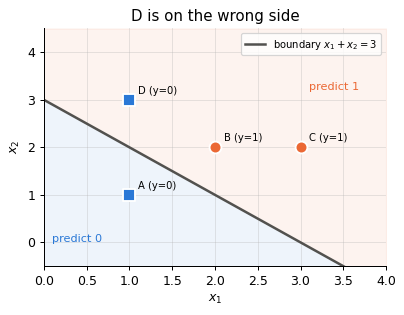

In [20]:
# Section 19 check
X_lr = np.array([[1, 1], [2, 2], [3, 2], [1, 3.0]])
y_lr = np.array([0, 1, 1, 0])
w_lr, b_lr = np.array([1.0, 1.0]), -3.0

def logistic_cost(w, b, X=X_lr, y=y_lr):
    return log_loss(y, expit(X @ w + b))                         # expit = sigmoid; log_loss = mean of -ln(...)

z_lr = X_lr @ w_lr + b_lr
f_lr = expit(z_lr)
print("z =", z_lr, " f =", f_lr.round(6), " predicted =", (z_lr >= 0).astype(int), " actual =", y_lr)
for name, v, h in zip("ABCD", f_lr, [0.268941, 0.731059, 0.880797, 0.731059]):
    check(f"f({name})", v, h, dp=6)
check("cost J", logistic_cost(w_lr, b_lr), 0.5167)

err = f_lr - y_lr
grad_w, grad_b = X_lr.T @ err / 4, err.mean()
check("dJ/dw1", grad_w[0], 0.026127, dp=6); check("dJ/dw2", grad_w[1], 0.421457, dp=6); check("dJ/db", grad_b, 0.152964, dp=6)

h = 1e-6                                                         # gradient checking with finite differences
num_w1 = (logistic_cost(w_lr + [h, 0], b_lr) - logistic_cost(w_lr - [h, 0], b_lr)) / (2 * h)
assert np.isclose(num_w1, grad_w[0], atol=1e-8)
print(f"finite-difference dJ/dw1 = {num_w1:.6f} (matches the formula)")

w_new, b_new = w_lr - 0.5 * grad_w, b_lr - 0.5 * grad_b
check("new w1", w_new[0], 0.9869); check("new w2", w_new[1], 0.7893); check("new b", b_new, -3.0765)
check("cost after the step", logistic_cost(w_new, b_new), 0.4436)

fig, ax = plt.subplots(figsize=(4.6, 3.6))
xs = np.linspace(0, 4, 50)
ax.plot(xs, 3 - xs, color=GRAY, lw=2, label="boundary $x_1 + x_2 = 3$")
ax.fill_between(xs, 3 - xs, 4.5, color=ORANGE, alpha=0.08)
ax.fill_between(xs, -0.5, 3 - xs, color=BLUE, alpha=0.08)
for (x1, x2), yy, name in zip(X_lr, y_lr, "ABCD"):
    ax.scatter(x1, x2, s=90, color=ORANGE if yy == 1 else BLUE, marker="o" if yy == 1 else "s",
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{name} (y={yy})", (x1, x2), textcoords="offset points", xytext=(7, 5), fontsize=8)
ax.text(3.1, 3.2, "predict 1", color=ORANGE, fontsize=9)
ax.text(0.1, 0.0, "predict 0", color=BLUE, fontsize=9)
ax.set(xlim=(0, 4), ylim=(-0.5, 4.5), xlabel="$x_1$", ylabel="$x_2$", title="D is on the wrong side")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Try it yourself.** $\mathbf w = (2, -1)$, $b = 0$. Classify the points $(1, 3)$ and $(2, 1)$, and compute the loss of $(2, 1)$ if its label is $y = 1$.

<details><summary>Answer</summary>

$(1, 3)$: $z = 2 - 3 = -1$, $f = 0.2689$ → class 0. $(2, 1)$: $z = 4 - 1 = 3$, $f = \sigma(3) = 0.9526$ → class 1; loss $= -\ln 0.9526 = 0.0486$.
</details>

**Common mistake:** using squared error as the cost for logistic regression. With a sigmoid inside it the squared error is non-convex (many local minima); the log loss is convex, so gradient descent finds the single best answer.

## 20. Softmax regression (multi-class): probabilities and loss for one example

**What it is:** with $K$ classes the model computes one score $z_k$ per class and turns the scores into probabilities with the **softmax**: $p_k = \dfrac{e^{z_k}}{\sum_j e^{z_j}}$. The loss is $-\ln p_{\text{true class}}$. **Analogy:** an election: $e^{z}$ is each candidate's vote count (always positive), and the probabilities are vote shares.

### Problem

An image classifier gives scores (logits) $z = (2, 1, -1)$ for (cat, dog, rabbit). The true class is **dog**. Compute the softmax probabilities, the cross-entropy loss and the gradient of the loss with respect to $z$.

### Solution by hand

1. Exponentials: $e^{2} = 7.389056$, $e^{1} = 2.718282$, $e^{-1} = 0.367879$; sum $= 10.475217$.
2. Probabilities: cat $7.389056 / 10.475217 = 0.7054$, dog $2.718282/10.475217 = 0.2595$, rabbit $0.367879/10.475217 = 0.0351$ (they add up to 1).
3. Loss $= -\ln p_{\text{dog}} = -\ln 0.259496 = 1.3490$. Shortcut without dividing: loss $= -z_{\text{dog}} + \ln \sum_j e^{z_j} = -1 + \ln 10.475217 = -1 + 2.349012 = 1.3490$.
4. Gradient: $\dfrac{\partial\, \text{loss}}{\partial z} = p - \text{onehot(dog)} = (0.7054,\ 0.2595 - 1,\ 0.0351) = (0.7054, -0.7405, 0.0351)$: training pushes the dog score up and the other two down.
5. With 2 classes and scores $(z, 0)$, softmax gives $\dfrac{e^z}{e^z + 1} = \sigma(z)$: logistic regression is the 2-class special case. For example $z = 1.5$: $\dfrac{4.481689}{4.481689 + 1} = 0.8176 = \sigma(1.5)$.

In [21]:
# Section 20 check
z_s = np.array([2.0, 1.0, -1.0])
p_s = softmax(z_s)
print("exp(z) =", np.exp(z_s).round(6), " sum =", np.exp(z_s).sum().round(6))
for name, v, h in zip(["cat", "dog", "rabbit"], p_s, [0.7054, 0.2595, 0.0351]):
    check(f"p({name})", v, h)
check("loss -ln p(dog)", -np.log(p_s[1]), 1.3490)
check("loss via log-sum-exp", -z_s[1] + np.log(np.exp(z_s).sum()), 1.3490)
check("loss (scikit-learn log_loss)", log_loss([1], [p_s], labels=[0, 1, 2]), 1.3490)
grad_z = p_s - np.array([0, 1, 0])
check("gradient for the dog score", grad_z[1], -0.7405)
check("softmax(1.5, 0) = sigmoid(1.5)", softmax([1.5, 0.0])[0], 0.8176)
assert np.isclose(softmax([1.5, 0.0])[0], expit(1.5))
assert np.allclose(softmax(z_s + 100), p_s)                      # adding a constant changes nothing

exp(z) = [7.389056 2.718282 0.367879]  sum = 10.475217
p(cat)                                   code =      0.7054   by hand =      0.7054   OK
p(dog)                                   code =      0.2595   by hand =      0.2595   OK
p(rabbit)                                code =      0.0351   by hand =      0.0351   OK
loss -ln p(dog)                          code =      1.3490   by hand =      1.3490   OK
loss via log-sum-exp                     code =      1.3490   by hand =      1.3490   OK
loss (scikit-learn log_loss)             code =      1.3490   by hand =      1.3490   OK
gradient for the dog score               code =     -0.7405   by hand =     -0.7405   OK
softmax(1.5, 0) = sigmoid(1.5)           code =      0.8176   by hand =      0.8176   OK


**Try it yourself.** (a) Scores $z = (3, 1, 1)$, true class = the first. Compute the probabilities and the loss. (b) What is the loss when all scores are equal, $z = (1, 1, 1)$?

<details><summary>Answer</summary>

(a) $e^3 = 20.085537$, $e^1 = 2.718282$ (twice), sum $= 25.522101$: $p = (0.7870, 0.1065, 0.1065)$; loss $= -\ln 0.7870 = 0.2395$. (b) every $p = 1/3$, loss $= \ln 3 = 1.0986$.
</details>

**Exam tip:** adding the same number to every score does not change the softmax, so libraries subtract $\max(z)$ first to avoid overflow in $e^{z}$.

## 21. Regularization: L1 and L2 penalties, regularized cost and gradient

**What it is:** a penalty on large weights added to the cost, so the model prefers simpler explanations and overfits less. **L2** (ridge) adds $\lambda\sum w_j^2$, **L1** (lasso) adds $\lambda\sum |w_j|$. **Analogy:** a tax on complexity: every unit of weight costs something, so the model only keeps weights that earn their keep.

### Problem

(a) Weights $\mathbf w = (0.5, -1.5, 2.0)$, $\lambda = 0.1$. Compute the L1 and L2 penalties. With learning rate $\alpha = 0.1$ and data-loss gradient $\mathbf g = (0.2, -0.4, 0.6)$, do one step with no penalty, with L2 and with L1.
(b) Course convention for linear regression: $J = \frac{1}{2m}\sum (f - y)^2 + \frac{\lambda}{2m}\sum_j w_j^2$. Taxi data (Section 11) at $(w, b) = (2, 0)$, $\lambda = 1$: compute $J$, the gradient and one step with $\alpha = 0.1$.
(c) Same convention for logistic regression on Section 19's data, $\lambda = 1$: compute the regularized cost and one step with $\alpha = 0.5$.

### Solution by hand

1. Penalties: L1 $= 0.1 \times (0.5 + 1.5 + 2.0) = 0.1 \times 4 = 0.4$; L2 $= 0.1 \times (0.25 + 2.25 + 4) = 0.1 \times 6.5 = 0.65$.
2. Penalty gradients: L2 gives $2\lambda\mathbf w = 0.2\,\mathbf w = (0.1, -0.3, 0.4)$; L1 gives $\lambda\,\text{sign}(\mathbf w) = (0.1, -0.1, 0.1)$.

| | total gradient | new $\mathbf w = \mathbf w - 0.1 \times$ gradient |
|---|---|---|
| no penalty | (0.2, −0.4, 0.6) | (0.48, −1.46, 1.94) |
| L2 | (0.3, −0.7, 1.0) | (0.47, −1.43, 1.90) |
| L1 | (0.3, −0.5, 0.7) | (0.47, −1.45, 1.93) |

   **Weight decay** view of L2: $\mathbf w_{new} = (1 - 2\alpha\lambda)\,\mathbf w - \alpha\mathbf g = 0.98\,\mathbf w - \alpha \mathbf g$: every step first shrinks each weight by 2% of itself (2.0 loses 0.04, 0.5 loses 0.01). L1 instead takes the same 0.01 off every weight's size, which can push small weights all the way to exactly 0 (a sparse model that ignores useless features).
3. (b) The penalty's gradient is $\frac{\lambda}{m} w_j$; $b$ is not regularized. At $(2, 0)$: $f = (2, 4, 6, 8)$, errors $f - y = (-1, -1, -1, -1)$.
   - $J = \frac{4}{8} + \frac{1}{8} \times 2^2 = 0.5 + 0.5 = 1.0$
   - $\frac{\partial J}{\partial w} = \frac14(-1 - 2 - 3 - 4) + \frac14 \times 2 = -2.5 + 0.5 = -2.0$; $\frac{\partial J}{\partial b} = \frac14(-4) = -1$
   - step: $w = 2 - 0.1 \times (-2.0) = 2.2$, $b = 0 - 0.1 \times (-1) = 0.1$. Same as $w\,(1 - \alpha\lambda/m) - \alpha \times (\text{data gradient}) = 2 \times 0.975 + 0.25 = 2.2$ ✓ (without regularization $w$ would be 2.25).
4. (c) Logistic: $J_{reg} = 0.5167 + \frac{1}{2 \times 4}(1^2 + 1^2) = 0.5167 + 0.25 = 0.7667$.
   - gradients: $\frac{\partial J}{\partial w_1} = 0.026127 + \frac14 \times 1 = 0.276127$; $\frac{\partial J}{\partial w_2} = 0.421457 + 0.25 = 0.671457$; $\frac{\partial J}{\partial b} = 0.152964$ (unchanged)
   - step: $w_1 = 1 - 0.5 \times 0.276127 = 0.8619$, $w_2 = 1 - 0.5 \times 0.671457 = 0.6643$, $b = -3.0765$ (as in Section 19)

In [22]:
# Section 21 check
w21, lam, alpha, g = np.array([0.5, -1.5, 2.0]), 0.1, 0.1, np.array([0.2, -0.4, 0.6])
check("L1 penalty", lam * np.abs(w21).sum(), 0.4)
check("L2 penalty", lam * (w21 ** 2).sum(), 0.65)
steps = {"no penalty": w21 - alpha * g,
         "L2": w21 - alpha * (g + 2 * lam * w21),
         "L1": w21 - alpha * (g + lam * np.sign(w21))}
for name, hand in [("no penalty", [0.48, -1.46, 1.94]), ("L2", [0.47, -1.43, 1.90]), ("L1", [0.47, -1.45, 1.93])]:
    print(f"{name:10} new w = {steps[name].round(4)}")
    assert np.allclose(steps[name], hand)
assert np.allclose(steps["L2"], (1 - 2 * alpha * lam) * w21 - alpha * g)          # the weight-decay form

# (b) regularized linear regression, course convention
m, lam = 4, 1.0
w, b = 2.0, 0.0
e = w * x_taxi + b - y_taxi
check("regularized J (linear)", cost(w, b) + lam / (2 * m) * w ** 2, 1.0)
dw = (e * x_taxi).mean() + lam / m * w
check("dJ/dw with lambda", dw, -2.0)
check("new w", w - 0.1 * dw, 2.2)
check("new b", b - 0.1 * e.mean(), 0.1)

# (c) regularized logistic regression on Section 19's data
check("regularized J (logistic)", logistic_cost(w_lr, b_lr) + lam / (2 * m) * (w_lr ** 2).sum(), 0.7667)
grad_reg = grad_w + lam / m * w_lr
w_reg = w_lr - 0.5 * grad_reg
check("new w1", w_reg[0], 0.8619); check("new w2", w_reg[1], 0.6643); check("new b", b_lr - 0.5 * grad_b, -3.0765)

L1 penalty                               code =      0.4000   by hand =      0.4000   OK
L2 penalty                               code =      0.6500   by hand =      0.6500   OK
no penalty new w = [ 0.48 -1.46  1.94]
L2         new w = [ 0.47 -1.43  1.9 ]
L1         new w = [ 0.47 -1.45  1.93]
regularized J (linear)                   code =      1.0000   by hand =      1.0000   OK
dJ/dw with lambda                        code =     -2.0000   by hand =     -2.0000   OK
new w                                    code =      2.2000   by hand =      2.2000   OK
new b                                    code =      0.1000   by hand =      0.1000   OK
regularized J (logistic)                 code =      0.7667   by hand =      0.7667   OK
new w1                                   code =      0.8619   by hand =      0.8619   OK
new w2                                   code =      0.6643   by hand =      0.6643   OK
new b                                    code =     -3.0765   by hand =     -3.076

**Try it yourself.** $\mathbf w = (1, -2)$, $\lambda = 0.05$. Compute the L1 and L2 penalties, then one step with $\alpha = 0.1$ and data gradient $\mathbf g = (0.5, 0.5)$ for L2 and for L1.

<details><summary>Answer</summary>

L1 $= 0.05 \times 3 = 0.15$; L2 $= 0.05 \times 5 = 0.25$. L2 gradient $= \mathbf g + 2\lambda\mathbf w = (0.6, 0.3)$ → $\mathbf w = (0.94, -2.03)$. L1 gradient $= \mathbf g + \lambda\,\text{sign}(\mathbf w) = (0.55, 0.45)$ → $\mathbf w = (0.945, -2.045)$.
</details>

**Exam tip:** books scale the L2 penalty differently ($\lambda\sum w^2$, $\frac{\lambda}{2}\sum w^2$, $\frac{\lambda}{2m}\sum w^2$); the idea is identical, only the constant in the gradient changes. Read which one the question uses, and never regularize the bias $b$.

## 22. Bayes' theorem (the base-rate trap) and naive Bayes with Laplace smoothing

**What it is:** Bayes' theorem turns "how likely is the evidence if the hypothesis is true" into "how likely is the hypothesis given the evidence": $P(A \mid B) = \dfrac{P(B \mid A)\,P(A)}{P(B)}$. **Naive Bayes** applies it to classification, assuming the features are independent within each class. **Analogy:** a detective who weighs each clue separately and multiplies the odds.

### Problem

(a) A disease affects 1% of people. A test catches 90% of sick people (sensitivity) and correctly clears 95% of healthy people (specificity). You test positive. What is the chance you are sick?

(b) Will we play tennis? Predict for **Outlook = Overcast, Wind = Strong**, first without smoothing, then with Laplace smoothing ($\alpha = 1$).

| day | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Outlook | Sunny | Sunny | Overcast | Rainy | Rainy | Overcast | Sunny | Rainy |
| Wind | Weak | Strong | Weak | Weak | Strong | Strong | Weak | Weak |
| Play | No | No | Yes | Yes | No | Yes | Yes | Yes |

### Solution by hand

1. (a) $P(+) = P(+ \mid D)P(D) + P(+ \mid \text{healthy})P(\text{healthy}) = 0.9 \times 0.01 + 0.05 \times 0.99 = 0.009 + 0.0495 = 0.0585$
$$P(D \mid +) = \frac{0.009}{0.0585} = 0.1538$$
   Only about 15%! Count it with 10,000 people: 100 are sick and 90 of them test positive; 9,900 are healthy and 5% of them, 495, also test positive. Of the $90 + 495 = 585$ positives only 90 are sick: $90/585 = 0.1538$. The disease is so rare that false alarms outnumber real cases.
2. (b) Counts. Play = Yes on 5 days (3, 4, 6, 7, 8), No on 3 days (1, 2, 5). Priors $P(\text{Yes}) = 5/8 = 0.625$, $P(\text{No}) = 3/8 = 0.375$.

| | Sunny | Overcast | Rainy | Weak | Strong |
|---|---|---|---|---|---|
| Yes (5 days) | 1 | 2 | 2 | 4 | 1 |
| No (3 days) | 2 | 0 | 1 | 1 | 2 |

3. **No smoothing**: score = prior × $P(\text{Outlook} \mid \text{class})$ × $P(\text{Wind} \mid \text{class})$.
   - Yes: $0.625 \times \frac25 \times \frac15 = 0.625 \times 0.4 \times 0.2 = 0.05$
   - No: $0.375 \times \frac03 \times \frac23 = 0$

   Because "Overcast" never appeared with No, the model is 100% sure of Yes: one missing combination wipes out all the other evidence.
4. **Laplace smoothing**: $P(\text{value} \mid c) = \dfrac{\text{count} + 1}{N_c + k}$, where $k$ = number of possible values of that feature (Outlook: 3, Wind: 2).
   - Yes: $P(\text{Overcast} \mid \text{Yes}) = \frac{2 + 1}{5 + 3} = 0.375$, $P(\text{Strong} \mid \text{Yes}) = \frac{1 + 1}{5 + 2} = 0.285714$; score $= 0.625 \times 0.375 \times 0.285714 = 0.066964$
   - No: $P(\text{Overcast} \mid \text{No}) = \frac{0 + 1}{3 + 3} = 0.166667$, $P(\text{Strong} \mid \text{No}) = \frac{2 + 1}{3 + 2} = 0.6$; score $= 0.375 \times 0.166667 \times 0.6 = 0.0375$
5. Normalize: $P(\text{Yes} \mid x) = \dfrac{0.066964}{0.066964 + 0.0375} = \dfrac{0.066964}{0.104464} = 0.6410$ and $P(\text{No} \mid x) = 0.3590$. Prediction: **play**, now with a sensible confidence instead of 100%.

In [23]:
# Section 22 check
prev, sens, spec = 0.01, 0.90, 0.95
p_pos = sens * prev + (1 - spec) * (1 - prev)
check("P(test positive)", p_pos, 0.0585)
check("P(sick | positive)", sens * prev / p_pos, 0.1538)

tennis = pd.DataFrame({"Outlook": ["Sunny", "Sunny", "Overcast", "Rainy", "Rainy", "Overcast", "Sunny", "Rainy"],
                       "Wind": ["Weak", "Strong", "Weak", "Weak", "Strong", "Strong", "Weak", "Weak"],
                       "Play": ["No", "No", "Yes", "Yes", "No", "Yes", "Yes", "Yes"]})
print(pd.crosstab(tennis.Play, tennis.Outlook), "\n", pd.crosstab(tennis.Play, tennis.Wind))
enc = OrdinalEncoder()
X_t = enc.fit_transform(tennis[["Outlook", "Wind"]])
query = enc.transform(pd.DataFrame({"Outlook": ["Overcast"], "Wind": ["Strong"]}))
for alpha, hand_yes in [(1e-10, 1.0), (1.0, 0.6410)]:               # alpha ~ 0 means "no smoothing"
    nbc = CategoricalNB(alpha=alpha).fit(X_t, tennis.Play)
    proba = dict(zip(nbc.classes_, nbc.predict_proba(query)[0]))
    check(f"P(Yes | Overcast, Strong), alpha = {alpha:g}", proba["Yes"], hand_yes)
score_yes, score_no = 0.625 * 3 / 8 * 2 / 7, 0.375 * 1 / 6 * 3 / 5   # the hand scores with smoothing
check("score Yes (smoothed)", score_yes, 0.066964, dp=6)
check("score No (smoothed)", score_no, 0.0375)

P(test positive)                         code =      0.0585   by hand =      0.0585   OK
P(sick | positive)                       code =      0.1538   by hand =      0.1538   OK
Outlook  Overcast  Rainy  Sunny
Play                           
No              0      1      2
Yes             2      2      1 
 Wind  Strong  Weak
Play              
No         2     1
Yes        1     4
P(Yes | Overcast, Strong), alpha = 1e-10 code =      1.0000   by hand =      1.0000   OK
P(Yes | Overcast, Strong), alpha = 1     code =      0.6410   by hand =      0.6410   OK
score Yes (smoothed)                     code =    0.066964   by hand =    0.066964   OK
score No (smoothed)                      code =      0.0375   by hand =      0.0375   OK


**Try it yourself.** (a) Prevalence 2%, sensitivity 95%, specificity 90%: compute $P(\text{sick} \mid +)$. (b) With Laplace smoothing, predict for **Outlook = Sunny, Wind = Strong** on the tennis table.

<details><summary>Answer</summary>

(a) $\dfrac{0.95 \times 0.02}{0.95 \times 0.02 + 0.10 \times 0.98} = \dfrac{0.019}{0.117} = 0.1624$.
(b) Yes: $0.625 \times \frac{1+1}{5+3} \times \frac{1+1}{5+2} = 0.625 \times 0.25 \times 0.285714 = 0.044643$. No: $0.375 \times \frac{2+1}{3+3} \times \frac{2+1}{3+2} = 0.375 \times 0.5 \times 0.6 = 0.1125$. $P(\text{No} \mid x) = 0.1125/0.157143 = 0.7159$ → **don't play**.
</details>

**Common mistake:** forgetting the denominator $P(B)$ in Bayes' theorem (or the prior in naive Bayes). The tiny prior of a rare disease is exactly what keeps $P(\text{sick} \mid +)$ low.

## 23. k-nearest neighbours: Euclidean and Manhattan distance, majority vote, cosine similarity

**What it is:** to classify a new point, find the $k$ closest training points and let them vote. **Analogy:** guessing someone's favourite football team from the teams of their closest neighbours on the street.

- Euclidean distance: $d = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2}$, the straight line
- Manhattan distance: $d = |x_1 - y_1| + |x_2 - y_2|$, walking along city blocks
- Cosine similarity: $\cos\theta = \dfrac{\mathbf a \cdot \mathbf b}{\lVert \mathbf a \rVert\,\lVert \mathbf b \rVert}$, compares **direction** only (popular for text and embeddings)

### Problem

| point | P1 | P2 | P3 | P4 | P5 | P6 |
|---|---|---|---|---|---|---|
| $(x_1, x_2)$ | (1, 2) | (2, 4) | (2, 1) | (5, 3) | (4, 5) | (6, 0) |
| class | A | A | A | B | B | B |

(a) Classify $Q = (4, 3)$ with $k = 3$ and with $k = 5$ (Euclidean), and compare the Manhattan ranking. (b) Cosine similarity of two documents with word counts (ml, data, python, pizza): $d_1 = (2, 1, 0, 1)$, $d_2 = (1, 1, 1, 0)$.

### Solution by hand

1. Differences from $Q = (4, 3)$ and both distances:

| point | class | $(\Delta x_1, \Delta x_2)$ | Euclidean | Manhattan |
|---|---|---|---|---|
| P1 | A | (−3, −1) | $\sqrt{9+1} = \sqrt{10} = 3.1623$ | 4 |
| P2 | A | (−2, 1) | $\sqrt{4+1} = \sqrt5 = 2.2361$ | 3 |
| P3 | A | (−2, −2) | $\sqrt{4+4} = \sqrt8 = 2.8284$ | 4 |
| P4 | B | (1, 0) | 1 | 1 |
| P5 | B | (0, 2) | 2 | 2 |
| P6 | B | (2, −3) | $\sqrt{4+9} = \sqrt{13} = 3.6056$ | 5 |

2. Sorted by Euclidean distance: P4 (B) 1, P5 (B) 2, P2 (A) 2.2361, P3 (A) 2.8284, P1 (A) 3.1623, P6 (B) 3.6056.
   - $k = 3$: P4, P5, P2 → B, B, A → **B** (2 votes to 1)
   - $k = 5$: add P3, P1 → B, B, A, A, A → **A** (3 to 2). The answer depends on $k$!
3. Manhattan order: P4 1, P5 2, P2 3, then P1 and P3 tied at 4, P6 5. The 3 nearest are the same, so $k = 3$ still gives **B**.
4. Cosine similarity: $d_1 \cdot d_2 = 2 \times 1 + 1 \times 1 + 0 \times 1 + 1 \times 0 = 3$; $\lVert d_1 \rVert = \sqrt{4 + 1 + 0 + 1} = \sqrt6 = 2.4495$; $\lVert d_2 \rVert = \sqrt3 = 1.7321$; $\cos\theta = \dfrac{3}{\sqrt6\sqrt3} = \dfrac{3}{\sqrt{18}} = \dfrac{3}{4.2426} = 0.7071$.
5. Direction vs length: $\mathbf a = (1, 2)$ and $\mathbf b = (2, 4)$ have cosine similarity $\frac{2 + 8}{\sqrt5 \sqrt{20}} = \frac{10}{10} = 1$ (same direction) but Euclidean distance $\sqrt{1 + 4} = 2.2361$. A short and a long document about the same topic look identical to cosine.

In [24]:
# Section 23 check
X_knn = np.array([[1, 2], [2, 4], [2, 1], [5, 3], [4, 5], [6, 0.0]])
y_knn = np.array([0, 0, 0, 1, 1, 1])                         # 0 = class A, 1 = class B
names = np.array(["A", "B"])
Q = np.array([[4.0, 3.0]])
d_euc = np.sqrt(((X_knn - Q) ** 2).sum(axis=1))
d_man = np.abs(X_knn - Q).sum(axis=1)
print(pd.DataFrame({"class": names[y_knn], "Euclidean": d_euc.round(4), "Manhattan": d_man}, index=[f"P{i}" for i in range(1, 7)]))
for i, h in zip([0, 1, 2, 5], [3.1623, 2.2361, 2.8284, 3.6056]):
    check(f"Euclidean distance to P{i + 1}", d_euc[i], h)
for k, metric, hand in [(3, "euclidean", "B"), (5, "euclidean", "A"), (3, "manhattan", "B")]:
    pred = names[KNeighborsClassifier(n_neighbors=k, metric=metric).fit(X_knn, y_knn).predict(Q)[0]]
    print(f"k = {k}, {metric:9}: predicted class {pred} (by hand: {hand})")
    assert pred == hand

d1, d2 = np.array([[2, 1, 0, 1.0]]), np.array([[1, 1, 1, 0.0]])
check("cosine similarity d1, d2", cosine_similarity(d1, d2)[0, 0], 0.7071)
check("cosine of (1,2) and (2,4)", cosine_similarity([[1, 2]], [[2, 4]])[0, 0], 1.0)
check("Euclidean distance (1,2)-(2,4)", np.linalg.norm(np.array([1, 2]) - np.array([2, 4])), 2.2361)

   class  Euclidean  Manhattan
P1     A     3.1623        4.0
P2     A     2.2361        3.0
P3     A     2.8284        4.0
P4     B     1.0000        1.0
P5     B     2.0000        2.0
P6     B     3.6056        5.0
Euclidean distance to P1                 code =      3.1623   by hand =      3.1623   OK
Euclidean distance to P2                 code =      2.2361   by hand =      2.2361   OK
Euclidean distance to P3                 code =      2.8284   by hand =      2.8284   OK
Euclidean distance to P6                 code =      3.6056   by hand =      3.6056   OK
k = 3, euclidean: predicted class B (by hand: B)
k = 5, euclidean: predicted class A (by hand: A)
k = 3, manhattan: predicted class B (by hand: B)
cosine similarity d1, d2                 code =      0.7071   by hand =      0.7071   OK
cosine of (1,2) and (2,4)                code =      1.0000   by hand =      1.0000   OK
Euclidean distance (1,2)-(2,4)           code =      2.2361   by hand =      2.2361   OK


**Try it yourself.** (a) Same training points, classify $Q = (3, 4)$ with $k = 1$ and $k = 3$ (Euclidean). (b) Cosine similarity of $(1, 0, 1)$ and $(1, 1, 0)$.

<details><summary>Answer</summary>

(a) Distances: P1 $\sqrt8 = 2.8284$, P2 1, P3 $\sqrt{10} = 3.1623$, P4 $\sqrt5 = 2.2361$, P5 $\sqrt2 = 1.4142$, P6 5. Order: P2 (A), P5 (B), P4 (B), ... $k = 1$ → **A**; $k = 3$ → A, B, B → **B**.
(b) dot $= 1$, lengths $\sqrt2$ and $\sqrt2$, cosine $= 1/2 = 0.5$.
</details>

**Exam tip:** KNN uses raw distances, so scale the features first (Section 14), or the feature with the biggest units decides everything. Use an odd $k$ for two classes to avoid tied votes.

---
## Part D. Diagnosing and validating models

## 24. Bias and variance from error numbers, and reading learning curves

**What it is:** compare three error rates. **Baseline** (for example human-level) error = what is realistically achievable. **Avoidable bias** = training error − baseline (the model can't even fit the training data). **Variance** = cross-validation (CV) error − training error (it fits the training data but does not generalize). **Analogy:** a student who fails the practice questions they studied has a *bias* problem (didn't learn); one who aces the practice questions but fails new ones has a *variance* problem (memorized).

### Problem

(a) Four photo-tagging models (errors in %). Diagnose each and suggest what to try next. Use the rule of thumb "a gap above 2 percentage points is large".

| model | baseline (human) error | training error | CV error |
|---|---|---|---|
| A | 1.0 | 1.5 | 2.0 |
| B | 1.0 | 8.0 | 8.5 |
| C | 1.0 | 1.5 | 9.0 |
| D | 1.0 | 7.0 | 14.0 |

(b) Learning curves: errors (%) as the training set grows. Will more data help?

| training examples $m$ | 100 | 200 | 400 | 800 | 1600 |
|---|---|---|---|---|---|
| model 1, training error | 7.0 | 8.0 | 8.5 | 8.8 | 9.0 |
| model 1, CV error | 13.0 | 11.0 | 10.0 | 9.5 | 9.3 |
| model 2, training error | 0.0 | 0.5 | 1.0 | 1.5 | 2.0 |
| model 2, CV error | 16.0 | 12.0 | 9.0 | 7.0 | 5.5 |

### Solution by hand

1. Compute the two gaps for each model:

| model | avoidable bias = train − baseline | variance = CV − train | diagnosis | try next |
|---|---|---|---|---|
| A | 1.5 − 1.0 = 0.5 | 2.0 − 1.5 = 0.5 | good | ship it, or polish |
| B | 8.0 − 1.0 = 7.0 | 8.5 − 8.0 = 0.5 | **high bias** (underfitting) | bigger model, more or polynomial features, smaller $\lambda$, train longer |
| C | 1.5 − 1.0 = 0.5 | 9.0 − 1.5 = 7.5 | **high variance** (overfitting) | more data, larger $\lambda$, fewer features, simpler model, data augmentation |
| D | 7.0 − 1.0 = 6.0 | 14.0 − 7.0 = 7.0 | **both** | fix bias first (bigger model), then variance |

2. Learning curves at $m = 1600$:
   - Model 1: avoidable bias $= 9.0 - 1.0 = 8.0$, variance $= 9.3 - 9.0 = 0.3$. The two curves have met at a high error, and doubling the data from 800 to 1600 improved CV error by only $9.5 - 9.3 = 0.2$. **High bias: more data will not help**; change the model.
   - Model 2: avoidable bias $= 2.0 - 1.0 = 1.0$, variance $= 5.5 - 2.0 = 3.5$. The gap is large but CV error is still falling by $7.0 - 5.5 = 1.5$ points per doubling. **High variance: more data helps.**
3. Typical shapes: training error goes **up** with $m$ (harder to fit more points), CV error goes **down** (better generalization), and they approach each other.

model A: avoidable bias =  0.5, variance =  0.5 -> good
model B: avoidable bias =  7.0, variance =  0.5 -> high bias
model C: avoidable bias =  0.5, variance =  7.5 -> high variance
model D: avoidable bias =  6.0, variance =  7.0 -> both
model 1: at m = 1600 bias = 8.0, variance = 0.3, CV gain from the last doubling = 0.2
model 2: at m = 1600 bias = 1.0, variance = 3.5, CV gain from the last doubling = 1.5
model 1 variance at m = 1600             code =         0.3   by hand =         0.3   OK
model 2 variance at m = 1600             code =         3.5   by hand =         3.5   OK


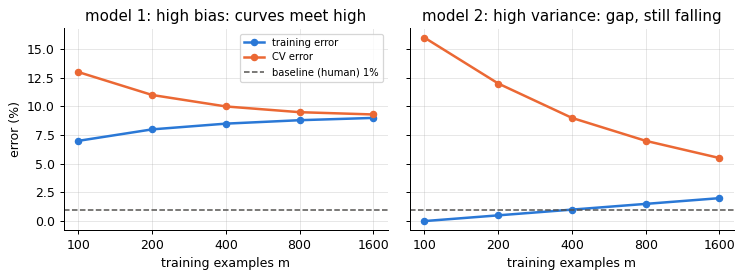

In [25]:
# Section 24 check
def diagnose(baseline, train, cv, big=2.0):
    bias, var = train - baseline, cv - train
    label = {(False, False): "good", (True, False): "high bias", (False, True): "high variance", (True, True): "both"}
    return round(bias, 4), round(var, 4), label[(bias > big, var > big)]

hand = {"A": (0.5, 0.5, "good"), "B": (7.0, 0.5, "high bias"), "C": (0.5, 7.5, "high variance"), "D": (6.0, 7.0, "both")}
errors = {"A": (1.0, 1.5, 2.0), "B": (1.0, 8.0, 8.5), "C": (1.0, 1.5, 9.0), "D": (1.0, 7.0, 14.0)}
for name, errs in errors.items():
    result = diagnose(*errs)
    print(f"model {name}: avoidable bias = {result[0]:4.1f}, variance = {result[1]:4.1f} -> {result[2]}")
    assert result == hand[name]

m_sizes = np.array([100, 200, 400, 800, 1600])
curves = {"model 1": (np.array([7.0, 8.0, 8.5, 8.8, 9.0]), np.array([13.0, 11.0, 10.0, 9.5, 9.3])),
          "model 2": (np.array([0.0, 0.5, 1.0, 1.5, 2.0]), np.array([16.0, 12.0, 9.0, 7.0, 5.5]))}
for name, (tr, cv) in curves.items():
    print(f"{name}: at m = 1600 bias = {tr[-1] - 1.0:.1f}, variance = {cv[-1] - tr[-1]:.1f}, "
          f"CV gain from the last doubling = {cv[-2] - cv[-1]:.1f}")
check("model 1 variance at m = 1600", curves["model 1"][1][-1] - curves["model 1"][0][-1], 0.3, dp=1)
check("model 2 variance at m = 1600", curves["model 2"][1][-1] - curves["model 2"][0][-1], 3.5, dp=1)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2), sharey=True)
for ax, (name, (tr, cv)), verdict in zip(axes, curves.items(), ["high bias: curves meet high", "high variance: gap, still falling"]):
    ax.plot(m_sizes, tr, "-o", color=BLUE, lw=2, ms=5, label="training error")
    ax.plot(m_sizes, cv, "-o", color=ORANGE, lw=2, ms=5, label="CV error")
    ax.axhline(1.0, ls="--", color=GRAY, lw=1.2, label="baseline (human) 1%")
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(m_sizes, [str(v) for v in m_sizes])
    ax.set(xlabel="training examples m", title=f"{name}: {verdict}")
axes[0].set_ylabel("error (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Try it yourself.** Baseline 1%. Model X: training 1.2%, CV 6.0%. Model Y: training 6.0%, CV 6.5%. Diagnose each and name one thing to try.

<details><summary>Answer</summary>

X: bias $0.2$, variance $4.8$ → **high variance**: get more data or regularize more. Y: bias $5.0$, variance $0.5$ → **high bias**: use a bigger model or add features.
</details>

**Exam tip:** without a baseline you can misread bias. A 10% training error is terrible for clean images (humans: 1%) but excellent for noisy speech if humans make 9.5% errors on it.

## 25. Train/dev/test split sizes and k-fold cross-validation arithmetic

**What it is:** the **training** set fits the parameters, the **dev** (validation) set chooses between models and settings, the **test** set gives one final, unbiased score. **k-fold cross-validation** splits the training data into $k$ folds and trains $k$ times, each time holding out a different fold. **Analogy:** practice exams (dev) to choose your study method, and the real exam (test) taken once.

### Problem

(a) Split 10,000 rows 60/20/20. If 5% of the rows are positive and the split is stratified, how many positives are in the dev set? (b) Split 1,000,000 rows 98/1/1. (c) 5-fold cross-validation on 103 rows: fold sizes and training sizes. The 5 fold accuracies are 0.80, 0.85, 0.75, 0.90, 0.70: compute the mean and the standard deviation. (d) A grid search tries 3 × 2 settings with 5-fold CV and then refits the best one: how many model fits? How many for leave-one-out CV on the 103 rows?

### Solution by hand

1. (a) $0.6 \times 10{,}000 = 6{,}000$ train, $0.2 \times 10{,}000 = 2{,}000$ dev, $2{,}000$ test. Stratified: the dev set keeps the 5% rate, $0.05 \times 2{,}000 = 100$ positives.
2. (b) $980{,}000$ / $10{,}000$ / $10{,}000$. With big data, 1% is already plenty to measure the error precisely (Section 26), so most rows go to training.
3. (c) $103 = 5 \times 20 + 3$: the first 3 folds get one extra row. Fold sizes **21, 21, 21, 20, 20** (sum 103 ✓); training sizes $103 - 21 = 82$ (three times) and $103 - 20 = 83$ (twice). Every row is tested exactly once and used for training 4 times.
4. Mean $= (0.80 + 0.85 + 0.75 + 0.90 + 0.70)/5 = 4.00/5 = 0.80$. Deviations $(0, 0.05, -0.05, 0.10, -0.10)$, squares $(0, 0.0025, 0.0025, 0.01, 0.01)$, sum $0.025$.
   Standard deviation (divide by $k$, as `np.std` does): $\sqrt{0.025/5} = \sqrt{0.005} = 0.0707$. Report **0.80 ± 0.07**. (Dividing by $k - 1$ gives $\sqrt{0.00625} = 0.0791$.)
5. (d) $3 \times 2 = 6$ settings × 5 folds $= 30$ fits, plus 1 refit of the best setting on all the training data $= 31$. Leave-one-out = $k = n$: 103 fits, each on 102 rows.

In [26]:
# Section 25 check
rows = np.arange(10_000)
labels = (rows % 20 == 0).astype(int)                         # exactly 5% positives
train_dev, test = train_test_split(rows, test_size=0.2, stratify=labels, random_state=SEED)
train, dev = train_test_split(train_dev, test_size=0.25, stratify=labels[train_dev], random_state=SEED)  # 0.25 of 80% = 20%
print("train / dev / test sizes:", len(train), len(dev), len(test))
assert (len(train), len(dev), len(test)) == (6000, 2000, 2000)
check("positives in the dev set", labels[dev].sum(), 100, dp=0)

fold_sizes = [len(test_idx) for _, test_idx in KFold(n_splits=5).split(np.arange(103))]
train_sizes = [len(train_idx) for train_idx, _ in KFold(n_splits=5).split(np.arange(103))]
print("fold sizes:", fold_sizes, " training sizes:", train_sizes)
assert fold_sizes == [21, 21, 21, 20, 20] and train_sizes == [82, 82, 82, 83, 83]

scores = np.array([0.80, 0.85, 0.75, 0.90, 0.70])
check("mean CV accuracy", scores.mean(), 0.80)
check("std (divide by k)", scores.std(), 0.0707)
check("std (divide by k - 1)", scores.std(ddof=1), 0.0791)
check("fits in the grid search", 3 * 2 * 5 + 1, 31, dp=0)

train / dev / test sizes: 6000 2000 2000
positives in the dev set                 code =         100   by hand =         100   OK
fold sizes: [21, 21, 21, 20, 20]  training sizes: [82, 82, 82, 83, 83]
mean CV accuracy                         code =      0.8000   by hand =      0.8000   OK
std (divide by k)                        code =      0.0707   by hand =      0.0707   OK
std (divide by k - 1)                    code =      0.0791   by hand =      0.0791   OK
fits in the grid search                  code =          31   by hand =          31   OK


**Try it yourself.** 4-fold cross-validation on 50 rows: give the fold sizes and training sizes. The fold scores are 0.7, 0.8, 0.9, 0.8: give the mean and standard deviation (divide by $k$).

<details><summary>Answer</summary>

$50 = 4 \times 12 + 2$: folds **13, 13, 12, 12**, training sizes 37, 37, 38, 38. Mean $= 3.2/4 = 0.8$; deviations $(-0.1, 0, 0.1, 0)$, std $= \sqrt{0.02/4} = \sqrt{0.005} = 0.0707$.
</details>

**Common mistake:** tuning on the test set. Once you pick a model because of its test score, that score is no longer an honest estimate; that is what the dev set (or cross-validation) is for ([model evaluation](06_model_evaluation/01_model_evaluation.ipynb)).

## 26. How many test examples do you need? Generalization gap and the Hoeffding bound

**What it is:** the **generalization gap** is test error − training error. The test error itself is only an *estimate* of the true error, measured on $m$ random examples. **Hoeffding's inequality** says how far off it can be: $P\big(|\hat e - e| > \varepsilon\big) \le 2e^{-2m\varepsilon^2}$. **Analogy:** a political poll: asking 1,000 people pins the true share down to a few percentage points, and asking 4 times as many people only halves the margin.

### Problem

(a) Training error 0.03, test error 0.12: what is the generalization gap? (b) How many test examples guarantee $|\hat e - e| \le \varepsilon$ with probability at least $1 - \delta = 95\%$, for $\varepsilon = 0.05$ and for $\varepsilon = 0.01$? (c) With $m = 1000$ test examples, what margin $\varepsilon$ do we get at 95%? (d) If we pick the best of $|H| = 1000$ models on the same dev set, how many examples does $\varepsilon = 0.05$, $\delta = 0.05$ need?

### Solution by hand

1. (a) Gap $= 0.12 - 0.03 = 0.09$: a sign of variance (overfitting), as in Section 24.
2. (b) Set $2e^{-2m\varepsilon^2} \le \delta$ and solve for $m$: $m \ge \dfrac{\ln(2/\delta)}{2\varepsilon^2}$. Here $\ln(2/0.05) = \ln 40 = 3.6889$.
   - $\varepsilon = 0.05$: $m \ge \dfrac{3.6889}{2 \times 0.0025} = \dfrac{3.6889}{0.005} = 737.8$, so **738** examples
   - $\varepsilon = 0.01$: $m \ge \dfrac{3.6889}{0.0002} = 18{,}444.4$, so **18,445** examples. A 5× tighter margin needs 25× more data ($m \propto 1/\varepsilon^2$).
3. (c) Solve for $\varepsilon$: $\varepsilon = \sqrt{\dfrac{\ln(2/\delta)}{2m}} = \sqrt{\dfrac{3.6889}{2000}} = \sqrt{0.0018444} = 0.0429$: "test error ± 4.3 points".
4. (d) Choosing among $|H|$ models costs a union bound: $m \ge \dfrac{\ln(2|H|/\delta)}{2\varepsilon^2} = \dfrac{\ln(40{,}000)}{0.005} = \dfrac{10.5966}{0.005} = 2119.3$, so **2,120** examples. 1000 times more models cost only about 2.9 times more data, because of the logarithm, but it is not free: heavy model selection on one dev set makes its score optimistic.
5. Hoeffding is a worst-case guarantee, so it is loose; the code simulates many test sets and finds the real failure rate is far below 5%.

In [27]:
# Section 26 check
check("generalization gap", 0.12 - 0.03, 0.09)
m_needed = lambda eps, delta, H=1: math.log(2 * H / delta) / (2 * eps ** 2)
check("ln(2/0.05)", math.log(40), 3.6889)
check("m for eps = 0.05 (before rounding up)", m_needed(0.05, 0.05), 737.8, dp=1)
check("m for eps = 0.01 (before rounding up)", m_needed(0.01, 0.05), 18444.4, dp=1)
check("eps for m = 1000", math.sqrt(math.log(40) / (2 * 1000)), 0.0429)
check("m for |H| = 1000 (before rounding up)", m_needed(0.05, 0.05, H=1000), 2119.3, dp=1)
print("rounded up:", [math.ceil(m_needed(*a)) for a in [(0.05, 0.05), (0.01, 0.05), (0.05, 0.05, 1000)]])

true_error, m, trials = 0.20, 738, 20_000          # simulate 20,000 test sets of 738 examples
est = rng.binomial(m, true_error, size=trials) / m
fail_rate = np.mean(np.abs(est - true_error) > 0.05)
print(f"share of test sets off by more than 0.05: {fail_rate:.4f} (Hoeffding promises at most 0.05)")
assert fail_rate <= 0.05

generalization gap                       code =      0.0900   by hand =      0.0900   OK
ln(2/0.05)                               code =      3.6889   by hand =      3.6889   OK
m for eps = 0.05 (before rounding up)    code =       737.8   by hand =       737.8   OK
m for eps = 0.01 (before rounding up)    code =     18444.4   by hand =     18444.4   OK
eps for m = 1000                         code =      0.0429   by hand =      0.0429   OK
m for |H| = 1000 (before rounding up)    code =      2119.3   by hand =      2119.3   OK
rounded up: [738, 18445, 2120]
share of test sets off by more than 0.05: 0.0006 (Hoeffding promises at most 0.05)


**Try it yourself.** How many test examples do you need for $\varepsilon = 0.02$ with 99% confidence ($\delta = 0.01$)?

<details><summary>Answer</summary>

$m \ge \dfrac{\ln(2/0.01)}{2 \times 0.02^2} = \dfrac{\ln 200}{0.0008} = \dfrac{5.2983}{0.0008} = 6622.9$, so **6,623** examples.
</details>

**Exam tip:** the margin shrinks like $1/\sqrt{m}$: to halve it you need 4 times the data. A model that is "1% better" on a 500-example test set may not be better at all. A deeper treatment of these bounds is in [statistical learning theory](16_learning_theory/01_statistical_learning_theory.ipynb).

---
## Recap cheat sheet

| # | Topic | Key formula | Remember |
|---|---|---|---|
| 1 | Confusion matrix | rows = actual, columns = predicted | scikit-learn: `[[TN, FP], [FN, TP]]` |
| 2 | Basic rates | accuracy $\frac{TP+TN}{n}$; precision $\frac{TP}{TP+FP}$; recall $\frac{TP}{TP+FN}$; specificity $\frac{TN}{TN+FP}$; FPR $= 1 -$ spec.; FNR $= 1 -$ recall | precision = column, recall = row |
| 3 | F1, F-beta | $F_1 = \frac{2PR}{P+R} = \frac{2TP}{2TP+FP+FN}$; $F_\beta = \frac{(1+\beta^2)PR}{\beta^2P+R}$ | harmonic mean punishes the weak side |
| 4 | Imbalance | majority-class accuracy is the floor | look at recall, F1, balanced accuracy |
| 5 | Threshold | predict 1 if $p \ge t$ | lower $t$: recall up, precision down |
| 6 | ROC / AUC / AP | AUC = trapezoid area = $P(s_+ > s_-)$; $AP = \sum (R_k - R_{k-1})P_k$ | AUC depends only on the ranking |
| 7 | Multi-class | macro = mean over classes; weighted = by support; micro = pooled counts | micro F1 = accuracy |
| 8 | Log loss | $-\frac1n \sum [y\ln p + (1-y)\ln(1-p)]$ | natural log; $\ln 2 = 0.6931$ for $p = 0.5$ |
| 9 | Regression metrics | MAE, MSE, RMSE $= \sqrt{\text{MSE}}$, $R^2 = 1 - SS_{res}/SS_{tot}$, MAPE | RMSE ≥ MAE; MAPE fails at $y = 0$ |
| 10 | Least squares | $w = \frac{n\Sigma xy - \Sigma x\Sigma y}{n\Sigma x^2 - (\Sigma x)^2}$, $b = \bar y - w\bar x$ | line passes through $(\bar x, \bar y)$ |
| 11 | Cost and GD | $J = \frac{1}{2m}\sum (f - y)^2$; $\frac{\partial J}{\partial w} = \frac1m\sum (f-y)x$; $w := w - \alpha\frac{\partial J}{\partial w}$ | simultaneous update |
| 12 | Learning rate | too small: slow; too large: $J$ rises | try 0.001, 0.003, 0.01, ... |
| 13 | Batch / SGD / mini-batch | 1 / $m$ / $m$ ÷ batch updates per epoch | smaller batches: more updates, more noise |
| 14 | Feature scaling | min-max $\frac{x - \min}{\max - \min}$; mean-norm $\frac{x-\mu}{\max-\min}$; z $\frac{x - \mu}{\sigma}$ | fit on training data only |
| 15 | Normal equation | $\boldsymbol\theta = (X^\top X)^{-1}X^\top\mathbf y$; $f = \mathbf w \cdot \mathbf x + b$ | 2 × 2 inverse: swap $a$ and $d$, negate $b$ and $c$, divide by $ad - bc$ |
| 16 | Polynomial features | add $x^2, x^3, \dots$ as new columns | still linear in the weights; scale them |
| 17 | Locally weighted regression | $w_i = \exp(-(x_i - x)^2 / 2\tau^2)$ | small $\tau$: local and wiggly |
| 18 | Newton's method | $w := w - J'(w)/J''(w)$ | quadratic $J$: one step; costs $n^3$ per step |
| 19 | Logistic regression | $f = \sigma(\mathbf w\cdot\mathbf x + b)$, boundary $\mathbf w \cdot \mathbf x + b = 0$; gradient $\frac1m\sum(f - y)x$ | log loss, not squared error |
| 20 | Softmax | $p_k = e^{z_k}/\sum_j e^{z_j}$; loss $-\ln p_{true}$; gradient $p - \text{onehot}$ | 2 classes = sigmoid |
| 21 | Regularization | L1 $\lambda\sum\lvert w\rvert$, L2 $\lambda\sum w^2$; course form $+\frac{\lambda}{2m}\sum w^2$, gradient $+\frac{\lambda}{m}w$ | L2 = weight decay; L1 makes zeros; don't regularize $b$ |
| 22 | Bayes / naive Bayes | $P(A\mid B) = \frac{P(B\mid A)P(A)}{P(B)}$; Laplace $\frac{\text{count}+1}{N_c + k}$ | base rates matter |
| 23 | KNN / cosine | Euclidean $\sqrt{\sum \Delta^2}$, Manhattan $\sum\lvert\Delta\rvert$; $\cos = \frac{a\cdot b}{\lVert a\rVert\lVert b\rVert}$ | scale features; answer depends on $k$ |
| 24 | Bias / variance | bias = train − baseline; variance = CV − train | bias: bigger model; variance: more data / regularize |
| 25 | Splits and k-fold | fold sizes differ by at most 1; fits = settings × $k$ + 1 | report mean ± std |
| 26 | Hoeffding | $m \ge \frac{\ln(2\lvert H\rvert/\delta)}{2\varepsilon^2}$; $\varepsilon = \sqrt{\ln(2/\delta)/2m}$ | margin shrinks like $1/\sqrt m$ |

## Related notebooks in this repo

| Topic | Notebook |
|---|---|
| Part 2 of these numericals: trees, ensembles, SVMs, clustering, PCA, EM, anomaly detection, recommenders, reinforcement learning | [00d_ml_numericals_part2_unsupervised_trees_rl.ipynb](00d_ml_numericals_part2_unsupervised_trees_rl.ipynb) |
| Your first model, end to end | [00_start_here_your_first_ml_model.ipynb](00_start_here_your_first_ml_model.ipynb) |
| Which algorithm when | [00b_20_ml_algorithms_cheatsheet.ipynb](00b_20_ml_algorithms_cheatsheet.ipynb) |
| Every metric in depth | [10_evaluation_metrics_comprehensive.ipynb](10_evaluation_metrics_comprehensive.ipynb) |
| Cross-validation, learning curves, model selection | [06_model_evaluation/01_model_evaluation.ipynb](06_model_evaluation/01_model_evaluation.ipynb) |
| Imbalanced data | [05_feature_engineering/02_imbalanced_data.ipynb](05_feature_engineering/02_imbalanced_data.ipynb) |
| Scaling and preprocessing | [01_supervised/00_preprocessing.ipynb](01_supervised/00_preprocessing.ipynb) |
| Linear regression | [01_supervised/01_linear_regression.ipynb](01_supervised/01_linear_regression.ipynb) |
| Logistic regression | [01_supervised/02_logistic_regression.ipynb](01_supervised/02_logistic_regression.ipynb) |
| Naive Bayes | [01_supervised/06_naive_bayes.ipynb](01_supervised/06_naive_bayes.ipynb) |
| k-nearest neighbours | [01_supervised/07_knn.ipynb](01_supervised/07_knn.ipynb) |
| Calibrated probabilities and thresholds | [01_supervised/13_model_calibration.ipynb](01_supervised/13_model_calibration.ipynb) |
| Generalization bounds | [16_learning_theory/01_statistical_learning_theory.ipynb](16_learning_theory/01_statistical_learning_theory.ipynb) |
| The perceptron, activations, backpropagation | [../05_Deep_Learning/01_neural_network_fundamentals.ipynb](../05_Deep_Learning/01_neural_network_fundamentals.ipynb) |
| Optimizers beyond plain gradient descent | [../05_Deep_Learning/02_optimizers.ipynb](../05_Deep_Learning/02_optimizers.ipynb) |
| The maths behind it | [../14_Mathematics/03_probability.ipynb](../14_Mathematics/03_probability.ipynb), [../14_Mathematics/06_optimization.ipynb](../14_Mathematics/06_optimization.ipynb) |

## Additional Learning Resources

- **Google Machine Learning Crash Course** (free): the *Classification* module (thresholds, confusion matrix, precision and recall, ROC and AUC) and the *Linear regression* module (loss, gradient descent, learning rate): https://developers.google.com/machine-learning/crash-course
- **StatQuest with Josh Starmer** (free videos): ROC and AUC, gradient descent step by step, naive Bayes, bias and variance, cross-validation: https://www.youtube.com/@statquest
- **scikit-learn user guide**: [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html), [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html)
- **Machine Learning Specialization** by Andrew Ng (DeepLearning.AI and Stanford, on Coursera): https://www.coursera.org/specializations/machine-learning-introduction
- **Stanford CS229: Machine Learning** (course page with public lecture notes): https://cs229.stanford.edu/
- **An Introduction to Statistical Learning** by James, Witten, Hastie and Tibshirani (free PDF): https://www.statlearning.com/
- T. Fawcett, "An introduction to ROC analysis", *Pattern Recognition Letters*, 2006: the classic paper on ROC curves and AUC.